<a href="https://colab.research.google.com/github/vaishnavir26-byte/ComAgent-Wireless-Optimization/blob/main/ComAgent_Wireless_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ComAgent-Inspired Wireless Resource Allocation Research

This notebook runs the **initial reproducible simulator and baseline comparison** for a research prototype inspired by *ComAgent: Multi-LLM Based Agentic AI Empowered Intelligent Wireless Networks*.

**Important:** The bundled multi-agent-role controller is deterministic/heuristic-only. It does not call an LLM. Do not describe its output as an LLM experiment or as a reproduction of the ComAgent paper. The wireless channel model is simplified and is not standards-compliant 5G/6G.

## Setup
Upload and extract `comagent_wireless_research.zip` in Colab first, or use the notebook from the extracted project folder. The next cell locates the package.


In [ ]:

%pip install -q numpy pandas scipy matplotlib

from pathlib import Path
from google.colab import files
import zipfile
import os
import sys

# 1. Upload the ZIP file
uploaded = files.upload()
zip_name = next(iter(uploaded))

# 2. Extract the ZIP into Colab's content directory
with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content")

# 3. Find the project directory
PROJECT_DIR = Path("/content/comagent_wireless_research")

if not (PROJECT_DIR / "comagent_sim").exists():
    matches = list(Path("/content").rglob("comagent_sim"))
    if matches:
        PROJECT_DIR = matches[0].parent
    else:
        raise FileNotFoundError(
            "Cannot find comagent_sim. "
            "Please check that you uploaded the correct project ZIP."
        )

# 4. Set up the working directory
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))

print("Project extracted successfully!")
print("Project directory:", PROJECT_DIR)
print("Simulator folder exists:", (PROJECT_DIR / "comagent_sim").exists())


Saving comagent_wireless_research.zip to comagent_wireless_research.zip
Project extracted successfully!
Project directory: /content/comagent_wireless_research
Simulator folder exists: True


## 1. Verify the simulator and allocation methods

In [ ]:
from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.algorithms import equal_allocation, random_allocation, greedy_allocation
from comagent_sim.agents import AdaptiveMultiAgentController

config = NetworkConfig(num_users=10, seed=42)
network = WirelessNetwork(config)
bw, power = equal_allocation(network)
metrics = network.evaluate(bw, power)

print(f"Aggregate throughput: {metrics['total_throughput_bps']/1e6:.4f} Mbps")
print(f"Mean user rate:       {metrics['mean_user_rate_bps']/1e6:.4f} Mbps")
print(f"Minimum user rate:    {metrics['minimum_user_rate_bps']/1e6:.4f} Mbps")
print("Constraints valid:", metrics["all_constraints_valid"])


Aggregate throughput: 30.3547 Mbps
Mean user rate:       3.0355 Mbps
Minimum user rate:    2.2324 Mbps
Constraints valid: True


## 2. Plot per-user throughput

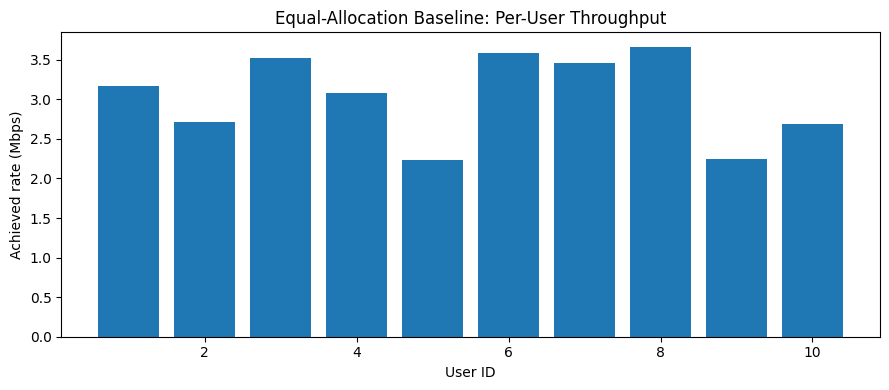

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.bar(np.arange(1, network.num_users + 1), metrics["user_rates_bps"] / 1e6)
plt.xlabel("User ID")
plt.ylabel("Achieved rate (Mbps)")
plt.title("Equal-Allocation Baseline: Per-User Throughput")
plt.tight_layout()
plt.show()


## 3. Run reproducible baseline comparison

The default experiment uses five seeds. Increase the number of seeds for stronger statistical evidence after checking runtime.

In [ ]:
from comagent_sim.experiments import run_comparison

df, summary = run_comparison(
    output_dir="results",
    seeds=(42, 43, 44, 45, 46),
    num_users=10,
)
display(df)
display(summary)


,seed,num_users,method,selected_candidate,candidate_count,throughput_mbps,mean_user_rate_mbps,minimum_user_rate_mbps,jain_fairness_index,bandwidth_used_mhz,power_used_w,constraints_valid,llm_enabled
0,42,10,equal,equal,1,30.354713,3.035471,2.232379,0.972406,10.0,1.0,True,False
1,42,10,random,random,1,28.130891,2.813089,0.034285,0.362754,10.0,1.0,True,False
2,42,10,greedy,greedy,1,36.641218,3.664122,0.000000,0.100000,10.0,1.0,True,False
3,42,10,proportional_fair,proportional_fair,1,30.354713,3.035471,2.232379,0.972406,10.0,1.0,True,False
4,42,10,adaptive_multi_agent_heuristic,equal,3,30.354713,3.035471,2.232379,0.972406,10.0,1.0,True,False
5,43,10,equal,equal,1,26.761696,2.676170,1.875831,0.960938,10.0,1.0,True,False
6,43,10,random,random,1,25.982606,2.598261,0.138753,0.411252,10.0,1.0,True,False
7,43,10,greedy,greedy,1,37.414636,3.741464,0.000000,0.100000,10.0,1.0,True,False
8,43,10,proportional_fair,proportional_fair,1,26.761696,2.676170,1.875831,0.960938,10.0,1.0,True,False
9,43,10,adaptive_multi_agent_heuristic,equal,3,26.761696,2.676170,1.875831,0.960938,10.0,1.0,True,False


,method,trials,throughput_mean_mbps,throughput_std_mbps,min_user_rate_mean_mbps,mean_jain_fairness,constraint_success_rate
0,adaptive_multi_agent_heuristic,5,29.426760,2.138335,2.116334,0.971418,1.0
1,equal,5,29.426760,2.138335,2.116334,0.971418,1.0
2,greedy,5,36.726033,1.252916,0.000000,0.100000,1.0
3,proportional_fair,5,29.426760,2.138335,2.116334,0.971418,1.0
4,random,5,28.111209,3.088856,0.131006,0.468995,1.0


## 4. View the generated graphs

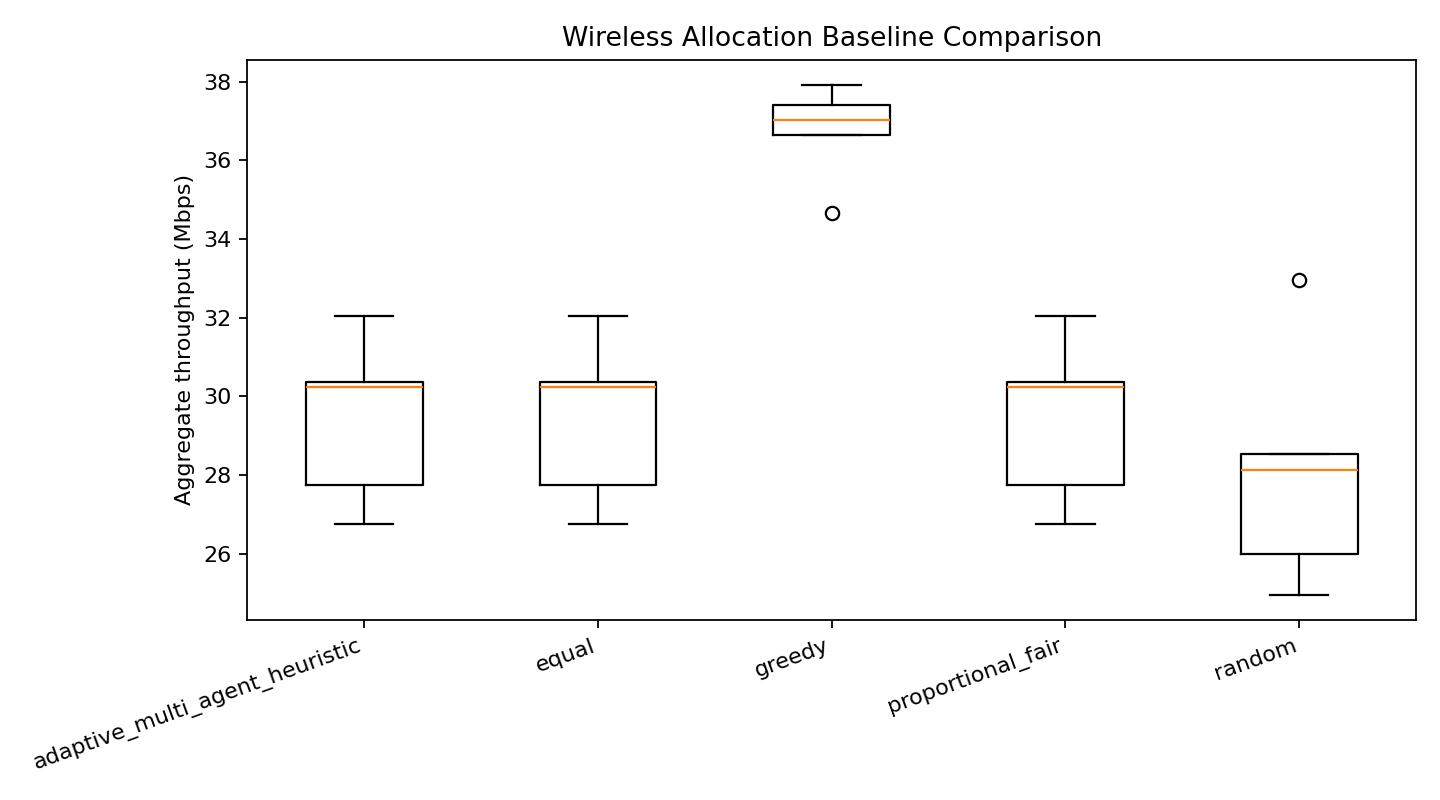

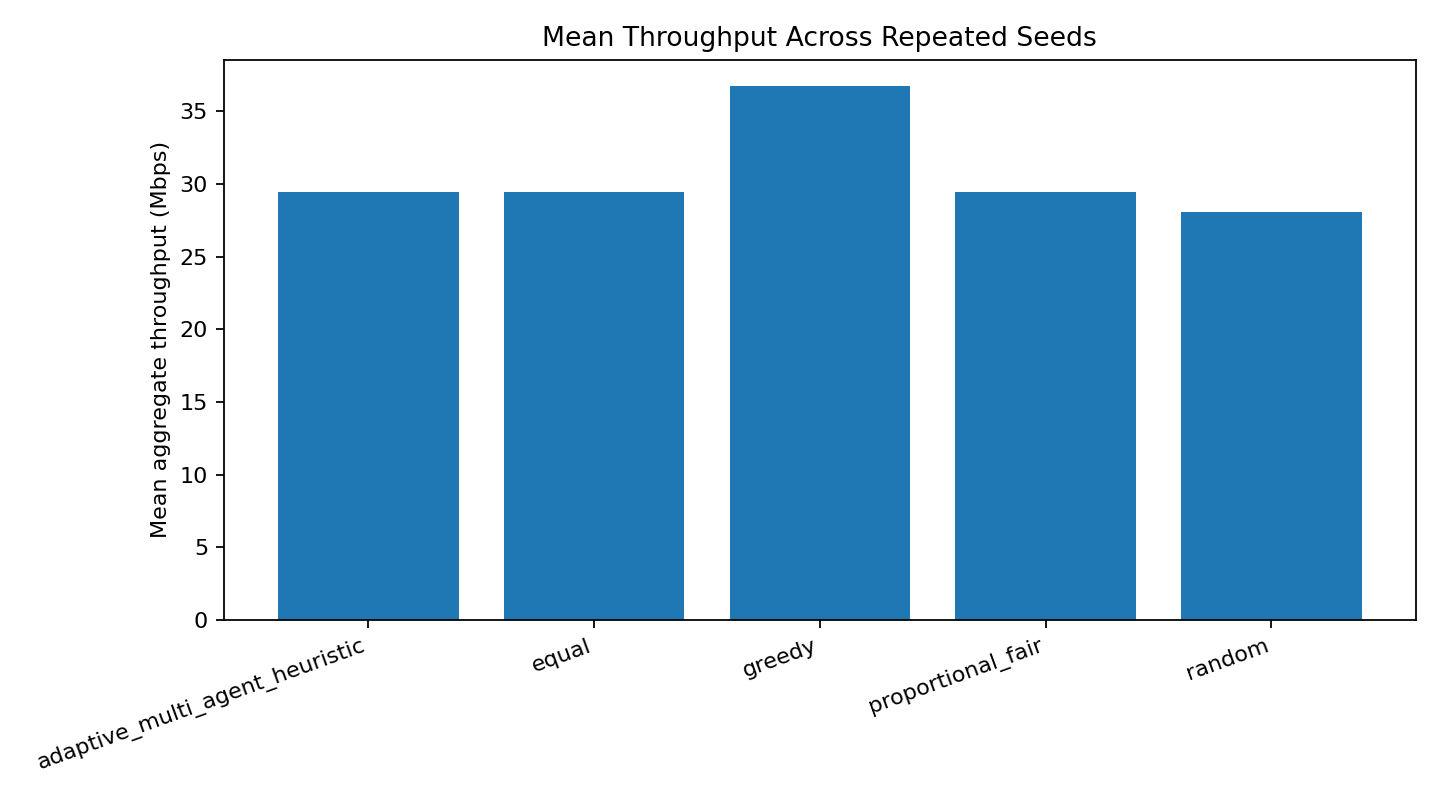

In [ ]:
from IPython.display import display, Image
display(Image(filename="results/throughput_comparison.png"))
display(Image(filename="results/mean_throughput.png"))


## 5. Run automated tests

In [ ]:
import subprocess, sys
completed = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    text=True, capture_output=True
)
print(completed.stdout)
print(completed.stderr)
if completed.returncode != 0:
    raise RuntimeError("Tests failed")
print("All tests passed.")



test_agent_controller_returns_valid_candidate (test_simulator.SimulatorTests.test_agent_controller_returns_valid_candidate) ... ok
test_equal_allocation_feasible (test_simulator.SimulatorTests.test_equal_allocation_feasible) ... ok
test_random_and_greedy_feasible (test_simulator.SimulatorTests.test_random_and_greedy_feasible) ... ok
test_reject_over_budget (test_simulator.SimulatorTests.test_reject_over_budget) ... ok
test_seed_reproducibility (test_simulator.SimulatorTests.test_seed_reproducibility) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.302s

OK

All tests passed.


## 6. Download experiment outputs

The CSVs, PNG plots, and experiment metadata are in the `results/` folder.

In [ ]:
from google.colab import files
files.download("results/comparison_results.csv")
files.download("results/summary_results.csv")
files.download("results/throughput_comparison.png")
files.download("results/mean_throughput.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Optional LLM-assisted planner/reviewer (not run by default)

The default comparisons above are API-free. To run the optional LLM workflow, install `requirements-llm.txt`, configure `OPENAI_API_KEY` and `OPENAI_MODEL` using Colab Secrets or environment variables, and optionally set `OPENAI_BASE_URL`. Check the provider's pricing and quotas first. Never hard-code or commit API keys.

This optional workflow has an LLM planner and reviewer, while Python generates candidates and validates constraints. It does not generate arbitrary executable code. Its API results are separate from the default experiment results.


In [ ]:
# OPTIONAL: this cell makes paid/limited API requests if credentials are configured.
# Keep credentials in Colab Secrets or environment variables; never paste them into the notebook.
import os, subprocess, sys
if os.getenv("OPENAI_API_KEY") and os.getenv("OPENAI_MODEL"):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openai"])
    from comagent_sim.llm_agents import LLMAdaptiveController
    llm_controller = LLMAdaptiveController()
    llm_result = llm_controller.run(network, seed=42)
    print("Selected candidate:", llm_result["selected_candidate"])
    print("LLM calls:", llm_result["llm_calls"])
    print("Prompt tokens:", llm_result["prompt_tokens"])
    print("Completion tokens:", llm_result["completion_tokens"])
    print("Fallbacks:", llm_result["planner_fallback"], llm_result["reviewer_fallback"])
else:
    print("Skipped: configure OPENAI_API_KEY and OPENAI_MODEL to explicitly enable the optional LLM workflow.")


Skipped: configure OPENAI_API_KEY and OPENAI_MODEL to explicitly enable the optional LLM workflow.


In [ ]:
%pip install -q pytest

In [ ]:

import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-v"],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

print("Test exit code:", result.returncode)


============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/comagent_wireless_research
plugins: anyio-4.15.1, typeguard-4.6.0, platformdirs-4.13.5, langsmith-0.14.12
collecting ... collected 5 items

tests/test_simulator.py::SimulatorTests::test_agent_controller_returns_valid_candidate PASSED [ 20%]
tests/test_simulator.py::SimulatorTests::test_equal_allocation_feasible PASSED [ 40%]
tests/test_simulator.py::SimulatorTests::test_random_and_greedy_feasible PASSED [ 60%]
tests/test_simulator.py::SimulatorTests::test_reject_over_budget PASSED  [ 80%]
tests/test_simulator.py::SimulatorTests::test_seed_reproducibility PASSED [100%]

============================== 5 passed in 0.60s ===============================

Test exit code: 0


In [ ]:

import subprocess
import sys
from pathlib import Path

PROJECT_DIR = Path.cwd()
print("Project:", PROJECT_DIR)

# Find the experiment scripts
for p in PROJECT_DIR.rglob("*.py"):
    if any(word in p.name.lower() for word in ["experiment", "baseline"]):
        print(p.relative_to(PROJECT_DIR))


Project: /content/comagent_wireless_research
run_experiments.py
comagent_sim/experiments.py


In [ ]:

import subprocess
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/comagent_wireless_research")
os.chdir(PROJECT_DIR)

result = subprocess.run(
    [sys.executable, "run_experiments.py"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("Errors or warnings:")
    print(result.stderr)

print("Exit code:", result.returncode)



Per-trial results:
 seed  num_users                         method selected_candidate  candidate_count  throughput_mbps  mean_user_rate_mbps  minimum_user_rate_mbps  jain_fairness_index  bandwidth_used_mhz  power_used_w  constraints_valid  llm_enabled
   42         10                          equal              equal                1        30.354713             3.035471                2.232379             0.972406                10.0           1.0               True        False
   42         10                         random             random                1        28.130891             2.813089                0.034285             0.362754                10.0           1.0               True        False
   42         10                         greedy             greedy                1        36.641218             3.664122                0.000000             0.100000                10.0           1.0               True        False
   42         10              proportional_fair 

In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/comagent_wireless_research")

print("Generated CSV and graph files:")

for p in PROJECT_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in {
        ".csv", ".png", ".jpg", ".json"
    }:
        print(p.relative_to(PROJECT_DIR))


Generated CSV and graph files:
results/comparison_results.csv
results/summary_results.csv
results/experiment_metadata.json
results/throughput_comparison.png
results/mean_throughput.png


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/comagent_wireless_research")

keywords = [
    "adaptive_multi_agent_heuristic",
    "selected_candidate",
    "jain_fairness",
]

for path in PROJECT_DIR.rglob("*.py"):
    if any(part in {"tests", "__pycache__"} for part in path.parts):
        continue

    try:
        lines = path.read_text().splitlines()
    except (UnicodeDecodeError, OSError):
        continue

    matches = [
        i for i, line in enumerate(lines)
        if any(word in line.lower() for word in keywords)
    ]

    if matches:
        print(f"\n{'=' * 60}")
        print("FILE:", path.relative_to(PROJECT_DIR))

        shown = set()
        for i in matches:
            start = max(0, i - 5)
            end = min(len(lines), i + 9)

            if any(j in shown for j in range(start, end)):
                continue

            print(f"\n--- Lines {start + 1}-{end} ---")
            for j in range(start, end):
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)



FILE: comagent_sim/agents.py

--- Lines 101-114 ---
 101:             if ok:
 102:                 utility = self.evaluator.score(metrics)
 103:                 evaluated.append(Candidate(name, bw, pw, metrics, utility))
 104:         chosen = self.reviewer.review(evaluated)
 105:         return {
 106:             "method": "adaptive_multi_agent_heuristic",
 107:             "selected_candidate": chosen.name,
 108:             "bandwidth_hz": chosen.bandwidth_hz,
 109:             "power_w": chosen.power_w,
 110:             "metrics": chosen.metrics,
 111:             "utility": chosen.utility,
 112:             "candidate_count": len(raw),
 113:             "valid_candidate_count": len(evaluated),
 114:             "channel_heterogeneity": plan["channel_heterogeneity"],

FILE: comagent_sim/llm_agents.py

--- Lines 117-130 ---
 117:             ],
 118:         }
 119:         try:
 120:             review = self._chat_json(
 121:                 "You are the reviewer agent. Select 

In [ ]:

import os
import numpy as np
import pandas as pd
from pathlib import Path

from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.agents import AdaptiveMultiAgentController

PROJECT_DIR = Path("/content/comagent_wireless_research")
os.chdir(PROJECT_DIR)

# Sensitivity experiment: different fairness weights
weights = [0.0, 0.15, 0.35, 0.50, 0.75, 1.0]
seeds = range(42, 52)  # 10 reproducible scenarios

rows = []

for weight in weights:
    for seed in seeds:
        net = WirelessNetwork(NetworkConfig(num_users=10, seed=seed))
        controller = AdaptiveMultiAgentController(
            fairness_weight=weight
        )
        result = controller.run(net, seed=seed + 1000)
        metrics = net.evaluate(
            result["bandwidth_hz"],
            result["power_w"]
        )

        rows.append({
            "seed": seed,
            "fairness_weight": weight,
            "selected_candidate": result["selected_candidate"],
            "throughput_mbps":
                metrics["total_throughput_bps"] / 1e6,
            "minimum_user_rate_mbps":
                metrics["minimum_user_rate_bps"] / 1e6,
            "jain_fairness":
                (metrics["user_rates_bps"].sum() ** 2 /
                 (len(metrics["user_rates_bps"]) *
                  (metrics["user_rates_bps"] ** 2).sum())),
            "constraints_valid":
                metrics["all_constraints_valid"],
        })

df = pd.DataFrame(rows)

out = PROJECT_DIR / "results" / "fairness_sensitivity"
out.mkdir(parents=True, exist_ok=True)

df.to_csv(out / "per_trial.csv", index=False)

summary = df.groupby("fairness_weight").agg(
    mean_throughput_mbps=("throughput_mbps", "mean"),
    mean_minimum_rate_mbps=("minimum_user_rate_mbps", "mean"),
    mean_jain_fairness=("jain_fairness", "mean"),
    constraint_success_rate=("constraints_valid", "mean"),
).reset_index()

summary.to_csv(out / "summary.csv", index=False)

print(summary.to_string(index=False))
print("\nCandidate selections:")
print(pd.crosstab(df["fairness_weight"], df["selected_candidate"]))
print("\nSaved results to:", out)


 fairness_weight  mean_throughput_mbps  mean_minimum_rate_mbps  mean_jain_fairness  constraint_success_rate
            0.00             36.156485                0.000000            0.100000                      1.0
            0.15             35.715231                0.220518            0.188029                      1.0
            0.35             29.403875                2.107878            0.974520                      1.0
            0.50             29.403875                2.107878            0.974520                      1.0
            0.75             29.403875                2.107878            0.974520                      1.0
            1.00             29.403875                2.107878            0.974520                      1.0

Candidate selections:
selected_candidate  equal  greedy
fairness_weight                  
0.00                    0      10
0.15                    1       9
0.35                   10       0
0.50                   10       0
0.75             

In [ ]:

from pathlib import Path

project = Path("/content/comagent_wireless_research")

for filename in ["agents.py", "optimization.py", "baselines.py"]:
    for path in project.rglob(filename):
        print(f"\n{'=' * 65}")
        print("FILE:", path.relative_to(project))

        lines = path.read_text().splitlines()
        for i, line in enumerate(lines):
            if any(term in line.lower() for term in [
                "class evalu", "def score", "def run",
                "def review", "candidate", "fairness_weight"
            ]):
                start = max(0, i - 2)
                end = min(len(lines), i + 8)
                print(f"\n--- Lines {start + 1}-{end} ---")
                for j in range(start, end):
                    print(f"{j + 1:4}: {lines[j]}")



FILE: comagent_sim/agents.py

--- Lines 2-11 ---
   2: 
   3: Default execution is deterministic and API-free. Separate agent roles implement
   4: planning, candidate generation, validation, evaluation, and review. This is an
   5: agentic heuristic prototype, not an LLM run unless an LLM provider is explicitly
   6: configured and actually invoked.
   7: """
   8: from __future__ import annotations
   9: from dataclasses import dataclass
  10: import numpy as np
  11: from .algorithms import (

--- Lines 16-25 ---
  16: 
  17: @dataclass
  18: class Candidate:
  19:     name: str
  20:     bandwidth_hz: np.ndarray
  21:     power_w: np.ndarray
  22:     metrics: dict
  23:     utility: float
  24: 
  25: 

--- Lines 27-36 ---
  27:     def plan(self, network):
  28:         heterogeneity = float(np.std(network.channel_gain) / (np.mean(network.channel_gain) + 1e-12))
  29:         # Adaptive candidate budget: simpler scenarios use fewer candidates.
  30:         methods = ["equal", "

In [ ]:

from pathlib import Path

project = Path("/content/comagent_wireless_research")

for filename in ["algorithms.py", "network.py", "models.py"]:
    matches = list(project.rglob(filename))
    for path in matches:
        print(f"\n{'=' * 70}\nFILE: {path}\n{'=' * 70}")
        lines = path.read_text().splitlines()

        # Print complete files when reasonably short.
        if len(lines) <= 250:
            print("\n".join(
                f"{i+1:4}: {line}"
                for i, line in enumerate(lines)
            ))
        else:
            terms = (
                "def equal_allocation",
                "def greedy_allocation",
                "def proportional_fair_allocation",
                "class Network",
                "def evaluate",
                "bandwidth_budget",
                "power_budget",
            )
            for i, line in enumerate(lines):
                if any(term in line for term in terms):
                    start, end = max(0, i-5), min(len(lines), i+30)
                    print("\n".join(
                        f"{j+1:4}: {lines[j]}"
                        for j in range(start, end)
                    ))
                    print("-" * 40)



FILE: /content/comagent_wireless_research/comagent_sim/algorithms.py
   1: """Conventional resource allocation baselines."""
   2: import numpy as np
   3: 
   4: 
   5: def equal_allocation(network):
   6:     k = network.num_users
   7:     return (
   8:         np.full(k, network.total_bandwidth_hz / k),
   9:         np.full(k, network.total_power_w / k),
  10:     )
  11: 
  12: 
  13: def random_allocation(network, seed=123):
  14:     """Generate a feasible random split of total bandwidth and power."""
  15:     rng = np.random.default_rng(seed)
  16:     k = network.num_users
  17:     bw = rng.dirichlet(np.ones(k)) * network.total_bandwidth_hz
  18:     power = rng.dirichlet(np.ones(k)) * network.total_power_w
  19:     return bw, power
  20: 
  21: 
  22: def greedy_allocation(network, bandwidth_chunks=100):
  23:     """Greedy bandwidth allocation using fixed equal power, one chunk at a time.
  24: 
  25:     Each chunk is assigned to the user with the highest marginal thr

In [ ]:

from pathlib import Path
import shutil

project = Path("/content/comagent_wireless_research")
alg_path = project / "comagent_sim" / "algorithms.py"
agents_path = project / "comagent_sim" / "agents.py"

# Back up original files before editing.
shutil.copy2(alg_path, alg_path.with_suffix(".py.bak"))
shutil.copy2(agents_path, agents_path.with_suffix(".py.bak"))

alg = alg_path.read_text()
agents = agents_path.read_text()

# 1. Add hybrid allocation function.
if "def hybrid_allocation(" not in alg:
    alg += '''

def hybrid_allocation(network, fairness_mix=0.5, bandwidth_chunks=100):
    """Hybrid bandwidth allocation blending throughput-greedy and
    proportional-fair allocations.

    fairness_mix=0 gives the greedy allocation;
    fairness_mix=1 gives the proportional-fair allocation.
    Power remains equally allocated to all users.
    """
    if not 0.0 <= fairness_mix <= 1.0:
        raise ValueError("fairness_mix must be in [0, 1]")

    greedy_bw, _ = greedy_allocation(
        network, bandwidth_chunks=bandwidth_chunks
    )
    fair_bw, _ = proportional_fair_allocation(
        network, bandwidth_chunks=bandwidth_chunks
    )

    bw = (1.0 - fairness_mix) * greedy_bw + fairness_mix * fair_bw
    power = np.full(
        network.num_users,
        network.total_power_w / network.num_users
    )
    return bw, power
'''

# 2. Import the new algorithm into agents.py.
if "hybrid_allocation" not in agents:
    start = agents.find("from .algorithms import (")
    if start == -1:
        raise RuntimeError("Could not find the algorithms import block.")

    end = agents.find(")", start)
    if end == -1:
        raise RuntimeError("Could not find the end of the import block.")

    import_block = agents[start:end]
    agents = (
        agents[:end]
        + "\n    hybrid_allocation,"
        + agents[end:]
    )

# 3. Register it as a candidate.
if '"hybrid": lambda: hybrid_allocation(network)' not in agents:
    old = '"proportional_fair": lambda: proportional_fair_allocation(network),'
    if old not in agents:
        raise RuntimeError("Could not find the proportional-fair generator entry.")
    agents = agents.replace(
        old,
        old + '\n            "hybrid": lambda: hybrid_allocation(network),',
        1
    )

# 4. Make the planner consider the hybrid candidate.
if 'methods.append("hybrid")' not in agents:
    old = 'methods = ["equal", "greedy"]'
    if old not in agents:
        raise RuntimeError("Could not find the planner's initial candidate list.")
    agents = agents.replace(
        old,
        old + '\n        methods.append("hybrid")',
        1
    )

alg_path.write_text(alg)
agents_path.write_text(agents)

print("Hybrid algorithm added.")
print("Backups saved as algorithms.py.bak and agents.py.bak")
print("\nRegistered candidate methods:")
print(agents_path.read_text()[agents_path.read_text().find("class PlannerAgent"):agents_path.read_text().find("class ValidatorAgent")])


Hybrid algorithm added.
Backups saved as algorithms.py.bak and agents.py.bak

Registered candidate methods:
class PlannerAgent:
    def plan(self, network):
        heterogeneity = float(np.std(network.channel_gain) / (np.mean(network.channel_gain) + 1e-12))
        # Adaptive candidate budget: simpler scenarios use fewer candidates.
        methods = ["equal", "greedy"]
        methods.append("hybrid")
        if heterogeneity >= 0.25:
            methods.append("proportional_fair")
        return {
            "objective": "balance aggregate throughput and user fairness",
            "constraints": ["sum bandwidth <= budget", "sum power <= budget", "nonnegative allocations"],
            "channel_heterogeneity": heterogeneity,
            "candidate_methods": methods,
            "candidate_budget": len(methods),
        }


class GeneratorAgent:
    def generate(self, network, plan, seed=123):
        methods = {
            "equal": lambda: equal_allocation(network),
            "g

In [ ]:

import sys
import numpy as np

project = "/content/comagent_wireless_research"
if project not in sys.path:
    sys.path.insert(0, project)

from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.algorithms import hybrid_allocation
from comagent_sim.agents import AdaptiveMultiAgentController

net = WirelessNetwork(NetworkConfig(num_users=10, seed=42))

# Test hybrid feasibility.
bw, power = hybrid_allocation(net, fairness_mix=0.5)
metrics = net.evaluate(bw, power)

assert metrics["all_constraints_valid"]
assert np.all(bw >= 0)
assert np.all(power >= 0)
assert np.isclose(bw.sum(), net.total_bandwidth_hz)
assert np.isclose(power.sum(), net.total_power_w)

# Test controller integration.
result = AdaptiveMultiAgentController().run(net, seed=1042)

assert result["metrics"]["all_constraints_valid"]
assert "hybrid" in result["candidate_methods"]

print("Hybrid feasibility test: PASSED")
print("Controller integration test: PASSED")
print("Selected candidate:", result["selected_candidate"])
print("Candidate methods:", result["candidate_methods"])
print("Throughput (Mbps):",
      result["metrics"]["total_throughput_bps"] / 1e6)
print("Minimum user rate (Mbps):",
      result["metrics"]["minimum_user_rate_bps"] / 1e6)


ImportError: cannot import name 'hybrid_allocation' from 'comagent_sim.algorithms' (/content/comagent_wireless_research/comagent_sim/algorithms.py)

In [ ]:

from pathlib import Path

project = Path("/content/comagent_wireless_research")
alg_path = project / "comagent_sim" / "algorithms.py"
agents_path = project / "comagent_sim" / "agents.py"

alg = alg_path.read_text()

# Add the missing function if it isn't present.
if "def hybrid_allocation(" not in alg:
    alg += '''

def hybrid_allocation(network, fairness_mix=0.5, bandwidth_chunks=100):
    """Blend throughput-greedy and proportional-fair bandwidth allocations."""
    if not 0.0 <= fairness_mix <= 1.0:
        raise ValueError("fairness_mix must be in [0, 1]")

    greedy_bw, _ = greedy_allocation(
        network, bandwidth_chunks=bandwidth_chunks
    )
    fair_bw, _ = proportional_fair_allocation(
        network, bandwidth_chunks=bandwidth_chunks
    )

    bw = (1.0 - fairness_mix) * greedy_bw + fairness_mix * fair_bw
    power = np.full(
        network.num_users,
        network.total_power_w / network.num_users
    )
    return bw, power
'''

alg_path.write_text(alg)

# Confirm that the function is now defined.
assert "def hybrid_allocation(" in alg_path.read_text()
print("Repair successful: hybrid_allocation is defined.")


Repair successful: hybrid_allocation is defined.


In [ ]:

agents = agents_path.read_text()

if "    hybrid_allocation," not in agents:
    start = agents.find("from .algorithms import (")
    if start == -1:
        raise RuntimeError("Algorithms import block not found in agents.py")

    end = agents.find(")", start)
    if end == -1:
        raise RuntimeError("Import block is incomplete")

    agents = agents[:end] + "\n    hybrid_allocation," + agents[end:]
    agents_path.write_text(agents)

print(agents_path.read_text().split("from .algorithms import (", 1)[1].split(")", 1)[0])



    equal_allocation, random_allocation, greedy_allocation,
    proportional_fair_allocation,

    hybrid_allocation,


In [ ]:

import sys
import numpy as np
from pathlib import Path

project = "/content/comagent_wireless_research"
if project not in sys.path:
    sys.path.insert(0, project)

# Clear cached modules so Python reloads the edited files.
for name in list(sys.modules):
    if name == "comagent_sim" or name.startswith("comagent_sim."):
        del sys.modules[name]

from comagent_sim.algorithms import hybrid_allocation
from comagent_sim.network import WirelessNetwork, NetworkConfig

net = WirelessNetwork(NetworkConfig(num_users=10, seed=42))
bw, power = hybrid_allocation(net, fairness_mix=0.5)
metrics = net.evaluate(bw, power)

print("Hybrid import: PASSED")
print("Constraints valid:", metrics["all_constraints_valid"])
print("Bandwidth used:", bw.sum(), "/", net.total_bandwidth_hz)
print("Power used:", power.sum(), "/", net.total_power_w)

assert metrics["all_constraints_valid"]
print("Hybrid test: PASSED")


Hybrid import: PASSED
Constraints valid: True
Bandwidth used: 10000000.0 / 10000000.0
Power used: 1.0 / 1.0
Hybrid test: PASSED


In [ ]:

import sys
from pathlib import Path

project = "/content/comagent_wireless_research"
if project not in sys.path:
    sys.path.insert(0, project)

from comagent_sim.agents import AdaptiveMultiAgentController
from comagent_sim.network import WirelessNetwork, NetworkConfig

net = WirelessNetwork(NetworkConfig(num_users=10, seed=42))
result = AdaptiveMultiAgentController().run(net, seed=1042)

print("Candidate methods:", result["candidate_methods"])
print("Selected candidate:", result["selected_candidate"])
print("Valid candidates:", result["valid_candidate_count"])
print("Constraints valid:", result["metrics"]["all_constraints_valid"])
print("Throughput (Mbps):",
      result["metrics"]["total_throughput_bps"] / 1e6)
print("Minimum user rate (Mbps):",
      result["metrics"]["minimum_user_rate_bps"] / 1e6)

assert "hybrid" in result["candidate_methods"], (
    "Hybrid is not registered in the planner."
)
assert result["metrics"]["all_constraints_valid"]
print("\nCONTROLLER TEST PASSED")


Candidate methods: ['equal', 'greedy', 'hybrid', 'proportional_fair']
Selected candidate: equal
Valid candidates: 4
Constraints valid: True
Throughput (Mbps): 30.354712661613014
Minimum user rate (Mbps): 2.2323791908079937

CONTROLLER TEST PASSED


In [ ]:

%cd /content/comagent_wireless_research
!python -m pytest -q


/content
.....                                                                    [100%]
5 passed in 0.46s


In [ ]:

%cd /content/comagent_wireless_research
!python run_experiments.py


/content

Per-trial results:
 seed  num_users                         method selected_candidate  candidate_count  throughput_mbps  mean_user_rate_mbps  minimum_user_rate_mbps  jain_fairness_index  bandwidth_used_mhz  power_used_w  constraints_valid  llm_enabled
   42         10                          equal              equal                1        30.354713             3.035471                2.232379             0.972406                10.0           1.0               True        False
   42         10                         random             random                1        28.130891             2.813089                0.034285             0.362754                10.0           1.0               True        False
   42         10                         greedy             greedy                1        36.641218             3.664122                0.000000             0.100000                10.0           1.0               True        False
   42         10              proportio

In [ ]:

import sys
import numpy as np
import pandas as pd

sys.path.insert(0, "/content/comagent_wireless_research")

from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.algorithms import (
    equal_allocation,
    greedy_allocation,
    proportional_fair_allocation,
    hybrid_allocation,
)

rows = []

for seed in range(42, 47):
    net = WirelessNetwork(NetworkConfig(num_users=10, seed=seed))

    methods = {
        "equal": lambda: equal_allocation(net),
        "greedy": lambda: greedy_allocation(net),
        "proportional_fair": lambda: proportional_fair_allocation(net),
        "hybrid_25": lambda: hybrid_allocation(net, fairness_mix=0.25),
        "hybrid_50": lambda: hybrid_allocation(net, fairness_mix=0.50),
        "hybrid_75": lambda: hybrid_allocation(net, fairness_mix=0.75),
    }

    for name, allocate in methods.items():
        bw, power = allocate()
        m = net.evaluate(bw, power)
        rates = np.asarray(m["user_rates_bps"], dtype=float)
        denom = len(rates) * np.sum(rates ** 2)
        jain = (rates.sum() ** 2 / denom) if denom > 0 else 0.0

        rows.append({
            "seed": seed,
            "method": name,
            "throughput_mbps": m["total_throughput_bps"] / 1e6,
            "minimum_rate_mbps": m["minimum_user_rate_bps"] / 1e6,
            "jain_fairness": jain,
            "constraints_valid": m["all_constraints_valid"],
        })

df = pd.DataFrame(rows)
print("Per-seed results:")
print(df.round(4).to_string(index=False))

print("\nMean results:")
print(
    df.groupby("method")
      .agg(
          throughput_mean_mbps=("throughput_mbps", "mean"),
          minimum_rate_mean_mbps=("minimum_rate_mbps", "mean"),
          fairness_mean=("jain_fairness", "mean"),
          constraint_success_rate=("constraints_valid", "mean"),
      )
      .round(4)
      .to_string()
)


Per-seed results:
 seed            method  throughput_mbps  minimum_rate_mbps  jain_fairness  constraints_valid
   42             equal          30.3547             2.2324         0.9724               True
   42            greedy          36.6412             0.0000         0.1000               True
   42 proportional_fair          30.3547             2.2324         0.9724               True
   42         hybrid_25          35.0696             0.5581         0.1516               True
   42         hybrid_50          33.4980             1.1162         0.2631               True
   42         hybrid_75          31.9263             1.6743         0.5435               True
   43             equal          26.7617             1.8758         0.9609               True
   43            greedy          37.4146             0.0000         0.1000               True
   43 proportional_fair          26.7617             1.8758         0.9609               True
   43         hybrid_25          34.7514  

In [ ]:

import sys
import numpy as np
import pandas as pd

sys.path.insert(0, "/content/comagent_wireless_research")

from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.algorithms import equal_allocation, greedy_allocation

def rate_floor_greedy(network, floor_fraction=0.75, bandwidth_chunks=100):
    """Maximize throughput subject to a minimum-rate floor.

    The floor is a fraction of the minimum user rate under equal allocation.
    Power is kept equal across users.
    """
    if not 0.0 <= floor_fraction <= 1.0:
        raise ValueError("floor_fraction must be in [0, 1]")

    k = network.num_users
    power = np.full(k, network.total_power_w / k)

    equal_bw, _ = equal_allocation(network)
    equal_metrics = network.evaluate(equal_bw, power)
    target_rate = (
        floor_fraction * equal_metrics["minimum_user_rate_bps"]
    )

    # Under this simulator's rate model, rate = bandwidth * spectral efficiency.
    spectral_efficiency = np.log2(
        1.0 + np.maximum(
            (power * network.channel_gain) /
            (network.config.noise_power_w + network.cross_coupling @ power),
            0.0
        )
    )

    if np.any(spectral_efficiency <= 0):
        raise ValueError("Non-positive spectral efficiency encountered")

    # Reserve enough bandwidth for every user to meet the target rate.
    bw = target_rate / spectral_efficiency
    remaining = network.total_bandwidth_hz - bw.sum()

    if remaining < -1e-6:
        raise RuntimeError("Rate-floor allocation exceeds bandwidth budget")

    # Allocate remaining chunks to the user with the highest throughput per Hz.
    chunks = max(int(bandwidth_chunks), k)
    chunk = network.total_bandwidth_hz / chunks
    n_chunks = max(0, int(np.floor(max(remaining, 0.0) / chunk)))

    best_user = int(np.argmax(spectral_efficiency))
    bw[best_user] += n_chunks * chunk

    # Distribute any small floating-point remainder.
    bw[best_user] += max(
        0.0, network.total_bandwidth_hz - bw.sum()
    )

    return bw, power


rows = []

for seed in range(42, 52):
    net = WirelessNetwork(NetworkConfig(num_users=10, seed=seed))

    methods = {
        "equal": lambda: equal_allocation(net),
        "greedy": lambda: greedy_allocation(net),
        "floor_50": lambda: rate_floor_greedy(net, 0.50),
        "floor_75": lambda: rate_floor_greedy(net, 0.75),
        "floor_100": lambda: rate_floor_greedy(net, 1.00),
    }

    for name, allocate in methods.items():
        bw, power = allocate()
        m = net.evaluate(bw, power)
        rates = np.asarray(m["user_rates_bps"], dtype=float)
        denom = len(rates) * np.sum(rates ** 2)
        jain = rates.sum() ** 2 / denom if denom > 0 else 0.0

        rows.append({
            "seed": seed,
            "method": name,
            "throughput_mbps": m["total_throughput_bps"] / 1e6,
            "minimum_rate_mbps": m["minimum_user_rate_bps"] / 1e6,
            "jain_fairness": jain,
            "constraints_valid": m["all_constraints_valid"],
        })

df_floor = pd.DataFrame(rows)

print("Mean results across 10 seeds:")
print(
    df_floor.groupby("method")
    .agg(
        throughput_mean_mbps=("throughput_mbps", "mean"),
        minimum_rate_mean_mbps=("minimum_rate_mbps", "mean"),
        fairness_mean=("jain_fairness", "mean"),
        constraint_success_rate=("constraints_valid", "mean"),
    )
    .round(4)
    .to_string()
)

assert df_floor["constraints_valid"].all()
print("\nAll tested allocations passed the constraint checks.")


Mean results across 10 seeds:
           throughput_mean_mbps  minimum_rate_mean_mbps  fairness_mean  constraint_success_rate
method                                                                                         
equal                   29.4039                  2.1079         0.9745                      1.0
floor_100               30.6179                  2.1079         0.5412                      1.0
floor_50                33.3872                  1.0539         0.1926                      1.0
floor_75                32.0025                  1.5809         0.3062                      1.0
greedy                  36.1565                  0.0000         0.1000                      1.0

All tested allocations passed the constraint checks.


In [ ]:

import sys
import numpy as np
import pandas as pd

sys.path.insert(0, "/content/comagent_wireless_research")

from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.algorithms import equal_allocation, greedy_allocation


def fair_residual_allocation(
    network, floor_fraction=0.75, bandwidth_chunks=100, epsilon_bps=1.0
):
    """Meet a per-user rate floor, then allocate residual bandwidth
    by maximizing proportional-fair utility.
    """
    if not 0.0 <= floor_fraction <= 1.0:
        raise ValueError("floor_fraction must be in [0, 1]")

    k = network.num_users
    power = np.full(k, network.total_power_w / k)

    equal_bw, _ = equal_allocation(network)
    equal_metrics = network.evaluate(equal_bw, power)
    target = floor_fraction * equal_metrics["minimum_user_rate_bps"]

    interference = network.cross_coupling @ power
    sinr = (
        power * network.channel_gain
        / (network.config.noise_power_w + interference)
    )
    efficiency = np.log2(1.0 + np.maximum(sinr, 0.0))

    # Reserve the bandwidth needed for every user to reach the target rate.
    bw = target / np.maximum(efficiency, 1e-15)
    if bw.sum() > network.total_bandwidth_hz + 1e-6:
        raise RuntimeError("Rate floor is infeasible")

    remaining = network.total_bandwidth_hz - bw.sum()
    chunks = max(int(bandwidth_chunks), k)
    chunk = network.total_bandwidth_hz / chunks
    n_chunks = int(np.floor(remaining / chunk))

    # Allocate each remaining chunk to maximize sum(log(rate + epsilon)).
    for _ in range(n_chunks):
        best_user = None
        best_utility = -np.inf

        for i in range(k):
            trial = bw.copy()
            trial[i] += chunk
            rates = network.evaluate(trial, power)["user_rates_bps"]
            utility = float(np.log(rates + epsilon_bps).sum())

            if utility > best_utility:
                best_user = i
                best_utility = utility

        bw[best_user] += chunk

    # Use any tiny remainder without violating the total budget.
    remainder = network.total_bandwidth_hz - bw.sum()
    if remainder > 0:
        rates = network.evaluate(bw, power)["user_rates_bps"]
        utilities = np.log(rates + epsilon_bps)
        i = int(np.argmin(utilities))
        bw[i] += remainder

    return bw, power


rows = []

for seed in range(42, 52):
    net = WirelessNetwork(NetworkConfig(num_users=10, seed=seed))

    methods = {
        "equal": lambda: equal_allocation(net),
        "greedy": lambda: greedy_allocation(net),
        "fair_residual_50": lambda: fair_residual_allocation(net, 0.50),
        "fair_residual_75": lambda: fair_residual_allocation(net, 0.75),
        "fair_residual_100": lambda: fair_residual_allocation(net, 1.00),
    }

    for name, fn in methods.items():
        bw, power = fn()
        m = net.evaluate(bw, power)
        rates = np.asarray(m["user_rates_bps"], dtype=float)
        denom = len(rates) * np.sum(rates ** 2)
        jain = rates.sum() ** 2 / denom if denom > 0 else 0.0

        rows.append({
            "seed": seed,
            "method": name,
            "throughput_mbps": m["total_throughput_bps"] / 1e6,
            "minimum_rate_mbps": m["minimum_user_rate_bps"] / 1e6,
            "jain_fairness": jain,
            "constraints_valid": m["all_constraints_valid"],
        })

df_fair = pd.DataFrame(rows)

print("Mean results across 10 seeds:")
print(
    df_fair.groupby("method")
    .agg(
        throughput_mean_mbps=("throughput_mbps", "mean"),
        minimum_rate_mean_mbps=("minimum_rate_mbps", "mean"),
        fairness_mean=("jain_fairness", "mean"),
        constraint_success_rate=("constraints_valid", "mean"),
    )
    .round(4)
    .to_string()
)

assert df_fair["constraints_valid"].all()
print("\nAll allocations passed the constraint checks.")



Mean results across 10 seeds:
                   throughput_mean_mbps  minimum_rate_mean_mbps  fairness_mean  constraint_success_rate
method                                                                                                 
equal                           29.4039                  2.1079         0.9745                      1.0
fair_residual_100               29.3568                  2.1458         0.9761                      1.0
fair_residual_50                29.3711                  2.1782         0.9747                      1.0
fair_residual_75                29.3867                  2.1039         0.9747                      1.0
greedy                          36.1565                  0.0000         0.1000                      1.0

All allocations passed the constraint checks.


In [ ]:

from pathlib import Path
import sys

PROJECT = Path("/content/comagent_wireless_research")
assert PROJECT.exists(), f"Project folder not found: {PROJECT}"

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.algorithms import (
    equal_allocation,
    greedy_allocation,
    proportional_fair_allocation,
    hybrid_allocation,
)

print("Project found and simulator imports passed.")


Project found and simulator imports passed.


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

results = []

user_counts = [5, 10, 20, 50]
interference_levels = [0.0, 0.02, 0.1, 0.2]
seeds = range(42, 47)

for k in user_counts:
    for interference in interference_levels:
        for seed in seeds:
            net = WirelessNetwork(NetworkConfig(
                num_users=k,
                total_bandwidth_hz=10e6,
                total_power_w=1.0,
                cross_interference_scale=interference,
                seed=seed,
            ))

            methods = {
                "equal": lambda: equal_allocation(net),
                "greedy": lambda: greedy_allocation(
                    net, bandwidth_chunks=100
                ),
                "proportional_fair": lambda: proportional_fair_allocation(
                    net, bandwidth_chunks=100
                ),
                "hybrid_75": lambda: hybrid_allocation(
                    net, fairness_mix=0.75, bandwidth_chunks=100
                ),
            }

            for method_name, allocate in methods.items():
                bw, power = allocate()
                metrics = net.evaluate(bw, power)

                rates = np.asarray(metrics["user_rates_bps"], dtype=float)
                denom = len(rates) * np.sum(rates ** 2)
                jain = (
                    float(np.sum(rates) ** 2 / denom)
                    if denom > 0 else 0.0
                )

                results.append({
                    "num_users": k,
                    "interference_scale": interference,
                    "seed": seed,
                    "method": method_name,
                    "throughput_mbps":
                        metrics["total_throughput_bps"] / 1e6,
                    "minimum_rate_mbps":
                        metrics["minimum_user_rate_bps"] / 1e6,
                    "jain_fairness": jain,
                    "constraints_valid":
                        metrics["all_constraints_valid"],
                })

df_sweep = pd.DataFrame(results)

output_dir = Path("/content/comagent_wireless_research/results/scenario_sweep")
output_dir.mkdir(parents=True, exist_ok=True)

df_sweep.to_csv(output_dir / "per_trial_results.csv", index=False)

summary = (
    df_sweep.groupby(
        ["num_users", "interference_scale", "method"]
    )
    .agg(
        trials=("seed", "count"),
        throughput_mean_mbps=("throughput_mbps", "mean"),
        throughput_std_mbps=("throughput_mbps", "std"),
        minimum_rate_mean_mbps=("minimum_rate_mbps", "mean"),
        fairness_mean=("jain_fairness", "mean"),
        constraint_success_rate=("constraints_valid", "mean"),
    )
    .reset_index()
)

summary.to_csv(output_dir / "summary.csv", index=False)

print("Scenario sweep completed.")
print("Total trials:", len(df_sweep))
print("All constraints valid:", df_sweep["constraints_valid"].all())
print("\nSummary:")
print(summary.round(4).to_string(index=False))
print("\nSaved results to:", output_dir)


Scenario sweep completed.
Total trials: 320
All constraints valid: True

Summary:
 num_users  interference_scale            method  trials  throughput_mean_mbps  throughput_std_mbps  minimum_rate_mean_mbps  fairness_mean  constraint_success_rate
         5                0.00             equal       5              366.9383               2.6502                 71.6949         0.9997                      1.0
         5                0.00            greedy       5              373.9688               0.8398                  0.0000         0.2000                      1.0
         5                0.00         hybrid_75       5              368.6959               1.8881                 53.7712         0.7907                      1.0
         5                0.00 proportional_fair       5              366.9383               2.6502                 71.6949         0.9997                      1.0
         5                0.02             equal       5               39.7451               2.407

In [ ]:

from google.colab import files

files.download(
    "/content/comagent_wireless_research/results/scenario_sweep/summary.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import sys
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/comagent_wireless_research")
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from comagent_sim.network import WirelessNetwork, NetworkConfig
from comagent_sim.algorithms import (
    equal_allocation,
    greedy_allocation,
    proportional_fair_allocation,
    hybrid_allocation,
)


class CalibratedWirelessNetwork(WirelessNetwork):
    """Experimental model with received-power channel gains.

    This is a simplified research model, not a standards-compliant
    5G/6G channel simulator.
    """

    def __init__(self, config=None, **kwargs):
        super().__init__(config=config, **kwargs)

        rng = np.random.default_rng(self.config.seed + 9000)

        # Log-uniform direct channel power gains: 90–120 dB path loss.
        self.channel_gain = 10.0 ** rng.uniform(
            -12.0, -9.0, self.num_users
        )

    def evaluate(self, bandwidth_hz, power_w):
        bw = np.asarray(bandwidth_hz, dtype=float)
        power = np.asarray(power_w, dtype=float)
        expected = (self.num_users,)

        if bw.shape != expected or power.shape != expected:
            raise ValueError(f"Allocations must have shape {expected}")
        if not np.all(np.isfinite(bw)) or not np.all(np.isfinite(power)):
            raise ValueError("Allocations must be finite")

        bw_valid = bool(
            np.all(bw >= 0)
            and bw.sum() <= self.total_bandwidth_hz + 1e-6
        )
        power_valid = bool(
            np.all(power >= 0)
            and power.sum() <= self.total_power_w + 1e-9
        )

        # Cross-coupling is a dimensionless interference-leakage fraction.
        # Received interference scales with the interfering channel gain.
        interference = self.cross_coupling @ (
            power * self.channel_gain
        )

        sinr = (
            power * self.channel_gain
            / (self.config.noise_power_w + interference)
        )

        rates = bw * np.log2(1.0 + np.maximum(sinr, 0.0))
        valid = bw_valid and power_valid

        return {
            "total_throughput_bps": float(rates.sum()),
            "mean_user_rate_bps": float(rates.mean()),
            "minimum_user_rate_bps": float(rates.min()),
            "bandwidth_used_hz": float(bw.sum()),
            "power_used_w": float(power.sum()),
            "bandwidth_valid": bw_valid,
            "power_valid": power_valid,
            "all_constraints_valid": valid,
            "user_rates_bps": rates,
            "sinr": sinr,
            "interference_w": interference,
        }


def calibrated_network(num_users, interference_scale, seed):
    config = NetworkConfig(
        num_users=num_users,
        total_bandwidth_hz=10e6,
        total_power_w=1.0,
        noise_power_w=2e-13,
        cross_interference_scale=interference_scale,
        seed=seed,
    )
    return CalibratedWirelessNetwork(config)


# Sanity check on a small example.
net = calibrated_network(num_users=10, interference_scale=0.02, seed=42)
bw, power = equal_allocation(net)
metrics = net.evaluate(bw, power)

print("Calibrated model initialized.")
print("Channel gain range:",
      f"{net.channel_gain.min():.3e} to {net.channel_gain.max():.3e}")
print("Noise power (W):", net.config.noise_power_w)
print("Equal-allocation throughput (Mbps):",
      round(metrics["total_throughput_bps"] / 1e6, 4))
print("Minimum user rate (Mbps):",
      round(metrics["minimum_user_rate_bps"] / 1e6, 4))
print("Jain fairness:",
      round(
          np.sum(metrics["user_rates_bps"]) ** 2
          / (
              net.num_users
              * np.sum(np.asarray(metrics["user_rates_bps"]) ** 2)
          ),
          4
      ))
print("Constraints valid:", metrics["all_constraints_valid"])

assert metrics["all_constraints_valid"]
assert np.all(np.isfinite(metrics["user_rates_bps"]))


Calibrated model initialized.
Channel gain range: 1.473e-11 to 7.163e-10
Noise power (W): 2e-13
Equal-allocation throughput (Mbps): 26.6617
Minimum user rate (Mbps): 0.6691
Jain fairness: 0.6906
Constraints valid: True


In [ ]:

results = []

user_counts = [5, 10, 20, 50]
interference_levels = [0.0, 0.02, 0.1, 0.2]
seeds = range(42, 72)

for k in user_counts:
    for interference in interference_levels:
        for seed in seeds:
            net = calibrated_network(k, interference, seed)

            methods = {
                "equal": lambda: equal_allocation(net),
                "greedy": lambda: greedy_allocation(
                    net, bandwidth_chunks=50
                ),
                "proportional_fair": lambda: proportional_fair_allocation(
                    net, bandwidth_chunks=50
                ),
                "hybrid_75": lambda: hybrid_allocation(
                    net, fairness_mix=0.75, bandwidth_chunks=50
                ),
            }

            for method_name, allocate in methods.items():
                bw, power = allocate()
                m = net.evaluate(bw, power)
                rates = np.asarray(m["user_rates_bps"], dtype=float)
                denom = len(rates) * np.sum(rates ** 2)
                jain = (
                    float(rates.sum() ** 2 / denom)
                    if denom > 0 else 0.0
                )

                results.append({
                    "num_users": k,
                    "interference_scale": interference,
                    "seed": seed,
                    "method": method_name,
                    "throughput_mbps":
                        m["total_throughput_bps"] / 1e6,
                    "minimum_rate_mbps":
                        m["minimum_user_rate_bps"] / 1e6,
                    "jain_fairness": jain,
                    "constraints_valid": m["all_constraints_valid"],
                })

df_cal = pd.DataFrame(results)

out = PROJECT / "results" / "calibrated_sweep"
out.mkdir(parents=True, exist_ok=True)
df_cal.to_csv(out / "per_trial_results.csv", index=False)

# Mean, standard deviation, and 95% t-based confidence interval
# for the mean throughput across 30 independent scenario seeds.
from scipy.stats import t

def mean_ci(series):
    x = np.asarray(series, dtype=float)
    n = len(x)
    mean = x.mean()
    if n < 2:
        return pd.Series({
            "mean": mean, "std": np.nan,
            "ci95_low": np.nan, "ci95_high": np.nan
        })
    se = x.std(ddof=1) / np.sqrt(n)
    margin = t.ppf(0.975, n - 1) * se
    return pd.Series({
        "mean": mean,
        "std": x.std(ddof=1),
        "ci95_low": mean - margin,
        "ci95_high": mean + margin,
    })

group_cols = ["num_users", "interference_scale", "method"]

summary = (
    df_cal.groupby(group_cols)
    .agg(
        trials=("seed", "count"),
        throughput_mean_mbps=("throughput_mbps", "mean"),
        throughput_std_mbps=("throughput_mbps", "std"),
        minimum_rate_mean_mbps=("minimum_rate_mbps", "mean"),
        fairness_mean=("jain_fairness", "mean"),
        constraint_success_rate=("constraints_valid", "mean"),
    )
    .reset_index()
)

ci = (
    df_cal.groupby(group_cols)["throughput_mbps"]
    .apply(mean_ci)
    .unstack()
    .reset_index()
    .rename(columns={
        "mean": "throughput_ci_mean_mbps",
        "std": "throughput_ci_std_mbps",
        "ci95_low": "throughput_ci95_low_mbps",
        "ci95_high": "throughput_ci95_high_mbps",
    })
)

summary = summary.merge(ci, on=group_cols)
summary.to_csv(out / "summary.csv", index=False)

print("Trials:", len(df_cal))
print("All constraints valid:", bool(df_cal["constraints_valid"].all()))
print("Saved to:", out)
print("\nSelected summary (10 and 50 users):")
print(
    summary[summary["num_users"].isin([10, 50])]
    .round(4)
    .to_string(index=False)
)

assert df_cal["constraints_valid"].all()


Trials: 1920
All constraints valid: True
Saved to: /content/comagent_wireless_research/results/calibrated_sweep

Selected summary (10 and 50 users):
 num_users  interference_scale            method  trials  throughput_mean_mbps  throughput_std_mbps  minimum_rate_mean_mbps  fairness_mean  constraint_success_rate  throughput_ci_mean_mbps  throughput_ci_std_mbps  throughput_ci95_low_mbps  throughput_ci95_high_mbps
        10                0.00             equal      30               41.7466              10.2898                  1.0648         0.7461                      1.0                  41.7466                 10.2898                   37.9043                    45.5889
        10                0.00            greedy      30               80.0664               9.7433                  0.0000         0.1000                      1.0                  80.0664                  9.7433                   76.4282                    83.7045
        10                0.00         hybrid_75     

In [ ]:

import numpy as np

net = calibrated_network(
    num_users=10,
    interference_scale=0.02,
    seed=42
)

bw_equal, p_equal = equal_allocation(net)
bw_pf, p_pf = proportional_fair_allocation(net, bandwidth_chunks=100)

m_equal = net.evaluate(bw_equal, p_equal)
m_pf = net.evaluate(bw_pf, p_pf)

print("Equal bandwidth allocations (MHz):")
print(np.round(bw_equal / 1e6, 4))

print("\nProportional-fair bandwidth allocations (MHz):")
print(np.round(bw_pf / 1e6, 4))

print("\nMaximum allocation difference (Hz):",
      np.max(np.abs(bw_equal - bw_pf)))

print("Equal throughput (Mbps):",
      m_equal["total_throughput_bps"] / 1e6)

print("PF throughput (Mbps):",
      m_pf["total_throughput_bps"] / 1e6)

print("\nSINR range:",
      float(np.min(m_equal["sinr"])),
      "to",
      float(np.max(m_equal["sinr"])))

print("Noise power is fixed at:",
      net.config.noise_power_w, "W")




Equal bandwidth allocations (MHz):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Proportional-fair bandwidth allocations (MHz):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Maximum allocation difference (Hz): 0.0
Equal throughput (Mbps): 26.661713572322284
PF throughput (Mbps): 26.661713572322284

SINR range: 0.5900882643383943 to 59.68350653446161
Noise power is fixed at: 2e-13 W


In [ ]:

import numpy as np
import pandas as pd

class BandwidthNoiseNetwork(CalibratedWirelessNetwork):
    """Simplified model with receiver noise proportional to user bandwidth."""

    def evaluate(self, bandwidth_hz, power_w):
        bw = np.asarray(bandwidth_hz, dtype=float)
        power = np.asarray(power_w, dtype=float)
        expected = (self.num_users,)

        if bw.shape != expected or power.shape != expected:
            raise ValueError(f"Allocations must have shape {expected}")
        if not np.all(np.isfinite(bw)) or not np.all(np.isfinite(power)):
            raise ValueError("Allocations must be finite")

        bw_valid = bool(
            np.all(bw >= 0)
            and bw.sum() <= self.total_bandwidth_hz + 1e-6
        )
        power_valid = bool(
            np.all(power >= 0)
            and power.sum() <= self.total_power_w + 1e-9
        )

        # noise_power_w is the reference noise over the full bandwidth.
        noise_per_user = (
            self.config.noise_power_w
            * bw / self.total_bandwidth_hz
        )

        interference = self.cross_coupling @ (
            power * self.channel_gain
        )

        sinr = (
            power * self.channel_gain
            / np.maximum(noise_per_user + interference, 1e-30)
        )

        rates = bw * np.log2(1.0 + np.maximum(sinr, 0.0))
        valid = bw_valid and power_valid

        return {
            "total_throughput_bps": float(rates.sum()),
            "mean_user_rate_bps": float(rates.mean()),
            "minimum_user_rate_bps": float(rates.min()),
            "bandwidth_used_hz": float(bw.sum()),
            "power_used_w": float(power.sum()),
            "bandwidth_valid": bw_valid,
            "power_valid": power_valid,
            "all_constraints_valid": bool(valid),
            "user_rates_bps": rates,
            "sinr": sinr,
            "interference_w": interference,
        }


def bandwidth_noise_network(seed=42, users=10, interference=0.02):
    config = NetworkConfig(
        num_users=users,
        total_bandwidth_hz=10e6,
        total_power_w=1.0,
        noise_power_w=2e-13,
        cross_interference_scale=interference,
        seed=seed,
    )
    return BandwidthNoiseNetwork(config)


# Compare allocations under the new model.
net = bandwidth_noise_network()

methods = {
    "equal": lambda: equal_allocation(net),
    "greedy": lambda: greedy_allocation(net, bandwidth_chunks=100),
    "proportional_fair": lambda: proportional_fair_allocation(
        net, bandwidth_chunks=100
    ),
    "hybrid_75": lambda: hybrid_allocation(
        net, fairness_mix=0.75, bandwidth_chunks=100
    ),
}

rows = []
allocations = {}

for name, fn in methods.items():
    bw, power = fn()
    m = net.evaluate(bw, power)
    rates = np.asarray(m["user_rates_bps"], dtype=float)
    denom = len(rates) * np.sum(rates ** 2)
    jain = rates.sum() ** 2 / denom if denom > 0 else 0.0

    allocations[name] = bw
    rows.append({
        "method": name,
        "throughput_mbps": m["total_throughput_bps"] / 1e6,
        "minimum_rate_mbps": m["minimum_user_rate_bps"] / 1e6,
        "jain_fairness": jain,
        "constraints_valid": m["all_constraints_valid"],
    })

print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\nBandwidth allocations (MHz):")
for name, bw in allocations.items():
    print(name, np.round(bw / 1e6, 4))

print(
    "\nMax equal-vs-PF bandwidth difference (Hz):",
    np.max(np.abs(
        allocations["equal"] - allocations["proportional_fair"]
    ))
)


           method  throughput_mbps  minimum_rate_mbps  jain_fairness  constraints_valid
            equal          27.7379             0.7101         0.6961               True
           greedy          59.2323             0.0000         0.1000               True
proportional_fair          27.7379             0.7101         0.6961               True
        hybrid_75          36.0079             0.5335         0.2994               True

Bandwidth allocations (MHz):
equal [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
greedy [ 0.  0.  0.  0.  0.  0. 10.  0.  0.  0.]
proportional_fair [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
hybrid_75 [0.75 0.75 0.75 0.75 0.75 0.75 3.25 0.75 0.75 0.75]

Max equal-vs-PF bandwidth difference (Hz): 0.0


In [ ]:

import inspect
import numpy as np

from comagent_sim.algorithms import proportional_fair_allocation

net = bandwidth_noise_network(seed=42, users=10, interference=0.02)
power = np.full(net.num_users, net.total_power_w / net.num_users)

print("Channel gains:")
print(np.round(net.channel_gain, 14))

print("\nCurrent proportional-fair implementation:")
print(inspect.getsource(proportional_fair_allocation))

# Compare the proportional-fair objective for equal bandwidth
# and for an allocation that gives more bandwidth to one user.
equal_bw = np.full(net.num_users, net.total_bandwidth_hz / net.num_users)
test_bw = equal_bw.copy()
test_bw[np.argmax(net.channel_gain)] += 1e6
test_bw[np.argmin(net.channel_gain)] -= 1e6

for name, bw in [("Equal", equal_bw), ("Perturbed", test_bw)]:
    metrics = net.evaluate(bw, power)
    rates = np.asarray(metrics["user_rates_bps"], dtype=float)
    utility = np.log(rates + 1.0).sum()

    print(
        f"{name}: throughput={metrics['total_throughput_bps']/1e6:.4f} Mbps, "
        f"PF utility={utility:.4f}"
    )

bw_pf, _ = proportional_fair_allocation(net, bandwidth_chunks=100)
print("\nPF allocation (MHz):", np.round(bw_pf / 1e6, 4))


Channel gains:
[1.8570e-11 7.1270e-11 2.0270e-11 5.9988e-10 1.4730e-11 3.9373e-10
 7.1631e-10 1.3362e-10 2.4080e-11 1.2227e-10]

Current proportional-fair implementation:
def proportional_fair_allocation(network, bandwidth_chunks=100, epsilon_bps=1.0):
    """Greedy proportional-fair bandwidth allocation with equal power.

    Each chunk is assigned to maximize the increase in sum(log(rate + epsilon)).
    This favors a throughput/fairness trade-off rather than aggregate throughput
    alone. Power is split equally and kept feasible.
    """
    k = network.num_users
    power = np.full(k, network.total_power_w / k)
    bw = np.zeros(k)
    chunks = max(int(bandwidth_chunks), k)
    chunk = network.total_bandwidth_hz / chunks
    for _ in range(chunks):
        best_user, best_utility = None, -np.inf
        for i in range(k):
            trial = bw.copy()
            trial[i] += chunk
            rates = network.evaluate(trial, power)["user_rates_bps"]
            utility = float(np.l

In [ ]:

import numpy as np

net = bandwidth_noise_network(seed=42, users=10, interference=0.02)

bw, power = equal_allocation(net)
metrics = net.evaluate(bw, power)

noise_per_user = (
    net.config.noise_power_w * bw / net.total_bandwidth_hz
)
interference_per_user = metrics["interference_w"]

print("User | Noise (W) | Interference (W) | Interference / Noise")
for i, (noise, interference) in enumerate(
    zip(noise_per_user, interference_per_user)
):
    print(
        f"{i:4d} | {noise:.3e} | {interference:.3e} | "
        f"{interference / max(noise, 1e-30):.2f}"
    )

print("\nMedian interference/noise ratio:",
      np.median(interference_per_user / noise_per_user))



User | Noise (W) | Interference (W) | Interference / Noise
   0 | 2.000e-14 | 2.343e-12 | 117.16
   1 | 2.000e-14 | 2.170e-12 | 108.50
   2 | 2.000e-14 | 1.261e-12 | 63.05
   3 | 2.000e-14 | 1.521e-12 | 76.04
   4 | 2.000e-14 | 2.297e-12 | 114.85
   5 | 2.000e-14 | 2.042e-12 | 102.10
   6 | 2.000e-14 | 1.000e-12 | 50.01
   7 | 2.000e-14 | 1.553e-12 | 77.63
   8 | 2.000e-14 | 1.862e-12 | 93.12
   9 | 2.000e-14 | 2.616e-12 | 130.78

Median interference/noise ratio: 97.60956128921666


In [ ]:

import numpy as np
from scipy.optimize import minimize

net = bandwidth_noise_network(
    seed=42,
    users=10,
    interference=0.02
)

n = net.num_users
total_bw = net.total_bandwidth_hz
power = np.full(n, net.total_power_w / n)
epsilon_bps = 1.0

def pf_objective(bw):
    rates = np.asarray(
        net.evaluate(bw, power)["user_rates_bps"],
        dtype=float
    )
    return -np.sum(np.log(rates + epsilon_bps))

equal_bw = np.full(n, total_bw / n)

result = minimize(
    pf_objective,
    x0=equal_bw.copy(),
    method="SLSQP",
    bounds=[(0.0, total_bw)] * n,
    constraints=[{
        "type": "eq",
        "fun": lambda bw: np.sum(bw) - total_bw
    }],
    options={"maxiter": 1000, "ftol": 1e-10}
)

print("Optimizer success:", result.success)
print("Optimizer message:", result.message)
print("Equal allocation (MHz):",
      np.round(equal_bw / 1e6, 4))
print("Optimized allocation (MHz):",
      np.round(result.x / 1e6, 4))
print("Equal PF utility:", -pf_objective(equal_bw))
print("Optimized PF utility:", -pf_objective(result.x))
print("Bandwidth sum (MHz):", result.x.sum() / 1e6)
print("Minimum bandwidth (Hz):", result.x.min())

if result.success:
    print("Utility improvement:",
          (-pf_objective(result.x)) - (-pf_objective(equal_bw)))


Optimizer success: True
Optimizer message: Optimization terminated successfully
Equal allocation (MHz): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Optimized allocation (MHz): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Equal PF utility: 145.90363839324377
Optimized PF utility: 145.90363839324377
Bandwidth sum (MHz): 10.0
Minimum bandwidth (Hz): 1000000.0
Utility improvement: 0.0


In [ ]:

import numpy as np

def reliability_aware_allocation(
    network,
    target_rate_mbps=1.0,
    bandwidth_chunks=200,
):
    """
    Prototype reliability-aware bandwidth allocation.

    - Keeps power equally distributed.
    - Finds the bandwidth each user needs to meet a target rate.
    - If all targets cannot fit, scales the required allocations
      to remain within the bandwidth budget.
    - Distributes any remaining bandwidth to improve aggregate
      throughput.

    Note: scaling when targets are infeasible is a heuristic,
    not a globally optimal reliability-maximization solution.
    """
    n = network.num_users
    total_bw = network.total_bandwidth_hz
    power = np.full(n, network.total_power_w / n)
    target_bps = target_rate_mbps * 1e6

    # Find the minimum bandwidth required by each user.
    required_bw = np.zeros(n)
    individually_feasible = np.zeros(n, dtype=bool)

    for i in range(n):
        low, high = 0.0, total_bw

        # Check whether this user can meet the target even
        # when given the entire bandwidth budget.
        test_bw = np.zeros(n)
        test_bw[i] = total_bw
        max_rate = network.evaluate(
            test_bw, power
        )["user_rates_bps"][i]

        if max_rate < target_bps:
            required_bw[i] = total_bw
            continue

        individually_feasible[i] = True

        # Binary search for the minimum required bandwidth.
        for _ in range(60):
            mid = (low + high) / 2
            test_bw[i] = mid

            rate = network.evaluate(
                test_bw, power
            )["user_rates_bps"][i]

            if rate >= target_bps:
                high = mid
            else:
                low = mid

        required_bw[i] = high

    # If the target requirements exceed the budget,
    # use a feasible fallback allocation.
    if required_bw.sum() > total_bw:
        bw = required_bw * (total_bw / required_bw.sum())
        target_budget_feasible = False
    else:
        bw = required_bw.copy()
        target_budget_feasible = True

        # Allocate residual bandwidth by marginal total throughput.
        remaining = total_bw - bw.sum()

        if remaining > 1e-6:
            chunks = max(int(bandwidth_chunks), 1)
            chunk = remaining / chunks

            for _ in range(chunks):
                best_user = None
                best_throughput = -np.inf

                for i in range(n):
                    trial = bw.copy()
                    trial[i] += chunk

                    rates = network.evaluate(
                        trial, power
                    )["user_rates_bps"]

                    throughput = float(np.sum(rates))

                    if throughput > best_throughput:
                        best_throughput = throughput
                        best_user = i

                bw[best_user] += chunk

    # Correct small floating-point budget errors.
    bw[-1] += total_bw - bw.sum()

    metrics = network.evaluate(bw, power)
    rates = np.asarray(metrics["user_rates_bps"], dtype=float)

    return {
        "bandwidth_hz": bw,
        "power_w": power,
        "target_rate_bps": target_bps,
        "target_budget_feasible": target_budget_feasible,
        "individually_feasible": individually_feasible,
        "user_rates_bps": rates,
        "reliability": float(np.mean(rates >= target_bps)),
        "throughput_mbps": float(rates.sum() / 1e6),
        "min_rate_mbps": float(rates.min() / 1e6),
        "jain_fairness": float(
            rates.sum() ** 2 /
            (n * np.sum(rates ** 2))
        ) if np.sum(rates ** 2) > 0 else 0.0,
        "constraints_valid": bool(
            metrics["constraints_valid"]
        ),
    }



# Run the reliability-aware algorithm again
net = bandwidth_noise_network(
    seed=42,
    users=10,
    interference=0.02,
)

result = reliability_aware_allocation(
    net,
    target_rate_mbps=1.0,
    bandwidth_chunks=200,
)

# Validate constraints independently instead of relying on a
# particular key in the simulator's metrics dictionary.
bw = result["bandwidth_hz"]
power = result["power_w"]
metrics = net.evaluate(bw, power)

constraints_valid = bool(
    np.all(np.isfinite(bw))
    and np.all(np.isfinite(power))
    and np.all(bw >= -1e-9)
    and np.all(power >= -1e-12)
    and bw.sum() <= net.total_bandwidth_hz + 1e-5
    and power.sum() <= net.total_power_w + 1e-9
)

print("Reliability-aware allocation")
print("-----------------------------")
print("Target rate: 1.0 Mbps")
print("Bandwidth per user (MHz):",
      np.round(bw / 1e6, 4))
print("User rates (Mbps):",
      np.round(result["user_rates_bps"] / 1e6, 4))
print("Reliability:",
      f'{result["reliability"]:.1%}')
print("Total throughput:",
      f'{result["throughput_mbps"]:.4f} Mbps')
print("Minimum user rate:",
      f'{result["min_rate_mbps"]:.4f} Mbps')
print("Jain fairness:",
      f'{result["jain_fairness"]:.4f}')
print("All individual targets possible:",
      bool(np.all(result["individually_feasible"])))
print("All targets fit within bandwidth budget:",
      result["target_budget_feasible"])
print("Constraints valid:", constraints_valid)


KeyError: 'constraints_valid'

In [ ]:

import inspect
import numpy as np

# Inspect the function currently loaded in Colab.
source = inspect.getsource(reliability_aware_allocation)

old_line = '''        "constraints_valid": bool(
            metrics["constraints_valid"]
        ),
'''

if old_line not in source:
    print("The exact old line was not found.")
    print("Search the function source for 'constraints_valid':")
    print("\n".join(
        line for line in source.splitlines()
        if "constraints_valid" in line
    ))
else:
    # Rebuild and execute the corrected function definition.
    fixed_source = source.replace(old_line, "")
    exec(fixed_source, globals())
    print("Function definition repaired successfully.")


Function definition repaired successfully.


In [ ]:

net = bandwidth_noise_network(
    seed=42,
    users=10,
    interference=0.02,
)

result = reliability_aware_allocation(
    net,
    target_rate_mbps=1.0,
    bandwidth_chunks=200,
)

bw = result["bandwidth_hz"]
power = result["power_w"]
rates = result["user_rates_bps"]

constraints_valid = bool(
    np.all(np.isfinite(bw))
    and np.all(np.isfinite(power))
    and np.all(bw >= -1e-9)
    and np.all(power >= -1e-12)
    and bw.sum() <= net.total_bandwidth_hz + 1e-5
    and power.sum() <= net.total_power_w + 1e-9
)

print("Bandwidth (MHz):", np.round(bw / 1e6, 4))
print("User rates (Mbps):", np.round(rates / 1e6, 4))
print("Reliability:", f'{result["reliability"]:.1%}')
print("Total throughput:", f'{result["throughput_mbps"]:.4f} Mbps')
print("Minimum rate:", f'{result["min_rate_mbps"]:.4f} Mbps')
print("Jain fairness:", f'{result["jain_fairness"]:.4f}')
print("Constraints valid:", constraints_valid)


Bandwidth (MHz): [1.1967 0.4775 0.7287 0.1875 1.4122 0.2305 4.2198 0.3069 0.8404 0.3999]
User rates (Mbps): [ 1.      1.      1.      1.      1.      1.     25.6018  1.      1.
  1.    ]
Reliability: 100.0%
Total throughput: 34.6018 Mbps
Minimum rate: 1.0000 Mbps
Jain fairness: 0.1802
Constraints valid: True


In [ ]:

import numpy as np
import pandas as pd

def evaluate_allocation(bw, power, net, target_mbps=1.0):
    metrics = net.evaluate(bw, power)
    rates = np.asarray(metrics["user_rates_bps"], dtype=float)

    return {
        "Throughput (Mbps)": rates.sum() / 1e6,
        "Reliability (%)": 100 * np.mean(rates >= target_mbps * 1e6),
        "Minimum rate (Mbps)": rates.min() / 1e6,
        "Jain fairness": (
            rates.sum() ** 2 /
            (len(rates) * np.sum(rates ** 2))
            if np.sum(rates ** 2) > 0 else 0.0
        ),
        "Constraints valid": bool(
            np.all(bw >= -1e-9)
            and np.all(power >= -1e-12)
            and bw.sum() <= net.total_bandwidth_hz + 1e-5
            and power.sum() <= net.total_power_w + 1e-9
        ),
    }

net = bandwidth_noise_network(
    seed=42,
    users=10,
    interference=0.02,
)

# Existing baselines
equal_bw, equal_power = equal_allocation(net)
greedy_bw, greedy_power = greedy_allocation(
    net, bandwidth_chunks=200
)
pf_bw, pf_power = proportional_fair_allocation(
    net, bandwidth_chunks=200
)

# New method
ra = reliability_aware_allocation(
    net,
    target_rate_mbps=1.0,
    bandwidth_chunks=200,
)

results = {
    "Equal": evaluate_allocation(equal_bw, equal_power, net),
    "Greedy": evaluate_allocation(greedy_bw, greedy_power, net),
    "Proportional Fair": evaluate_allocation(pf_bw, pf_power, net),
    "Reliability Aware": evaluate_allocation(
        ra["bandwidth_hz"], ra["power_w"], net
    ),
}

comparison = pd.DataFrame(results).T
display(comparison.round(4))


,Throughput (Mbps),Reliability (%),Minimum rate (Mbps),Jain fairness,Constraints valid
Equal,27.737933,80.0,0.710111,0.696068,True
Greedy,59.232325,10.0,0.0,0.1,True
Proportional Fair,27.737933,80.0,0.710111,0.696068,True
Reliability Aware,34.601842,100.0,1.0,0.180191,True


In [ ]:

import numpy as np
import pandas as pd

rows = []

for seed in range(42, 72):
    net = bandwidth_noise_network(
        seed=seed,
        users=10,
        interference=0.02,
    )

    equal_bw, equal_power = equal_allocation(net)
    greedy_bw, greedy_power = greedy_allocation(
        net, bandwidth_chunks=200
    )
    pf_bw, pf_power = proportional_fair_allocation(
        net, bandwidth_chunks=200
    )

    ra = reliability_aware_allocation(
        net,
        target_rate_mbps=1.0,
        bandwidth_chunks=200,
    )

    allocations = {
        "Equal": (equal_bw, equal_power),
        "Greedy": (greedy_bw, greedy_power),
        "Proportional Fair": (pf_bw, pf_power),
        "Reliability Aware": (
            ra["bandwidth_hz"], ra["power_w"]
        ),
    }

    for method, (bw, power) in allocations.items():
        rates = np.asarray(
            net.evaluate(bw, power)["user_rates_bps"],
            dtype=float,
        )

        rows.append({
            "seed": seed,
            "method": method,
            "throughput_mbps": rates.sum() / 1e6,
            "reliability_pct": 100 * np.mean(rates >= 1e6),
            "min_rate_mbps": rates.min() / 1e6,
            "jain_fairness": (
                rates.sum() ** 2 /
                (len(rates) * np.sum(rates ** 2))
                if np.sum(rates ** 2) > 0 else 0.0
            ),
            "constraints_valid": bool(
                np.all(bw >= -1e-9)
                and np.all(power >= -1e-12)
                and bw.sum() <= net.total_bandwidth_hz + 1e-5
                and power.sum() <= net.total_power_w + 1e-9
            ),
        })

df = pd.DataFrame(rows)

summary = df.groupby("method").agg(
    mean_throughput_mbps=("throughput_mbps", "mean"),
    std_throughput_mbps=("throughput_mbps", "std"),
    mean_reliability_pct=("reliability_pct", "mean"),
    mean_min_rate_mbps=("min_rate_mbps", "mean"),
    mean_jain_fairness=("jain_fairness", "mean"),
    valid_trial_fraction=("constraints_valid", "mean"),
).round(4)

display(summary)

df.to_csv("comagent_30_seed_results.csv", index=False)
summary.to_csv("comagent_30_seed_summary.csv")

print("Trials:", len(df))
print("All constraints valid:", bool(df["constraints_valid"].all()))
print("Saved per-seed and summary CSV files.")


,mean_throughput_mbps,std_throughput_mbps,mean_reliability_pct,mean_min_rate_mbps,mean_jain_fairness,valid_trial_fraction
method,,,,,,
Equal,24.7282,2.9481,66.6667,0.2574,0.5834,1.0
Greedy,60.4056,9.0232,14.3333,0.0000,0.1234,1.0
Proportional Fair,24.7452,2.9578,66.6667,0.2574,0.5827,1.0
Reliability Aware,11.3066,9.5627,29.3333,0.7167,0.8104,1.0


Trials: 120
All constraints valid: True
Saved per-seed and summary CSV files.


In [ ]:

import numpy as np
import pandas as pd

def reliability_aware_allocation_v2(
    network,
    target_rate_mbps=1.0,
    bandwidth_chunks=200,
):
    n = network.num_users
    total_bw = network.total_bandwidth_hz
    power = np.full(n, network.total_power_w / n)
    target_bps = target_rate_mbps * 1e6

    # Estimate each user's minimum bandwidth requirement.
    required_bw = np.full(n, np.inf)
    individually_feasible = np.zeros(n, dtype=bool)

    for i in range(n):
        test_bw = np.zeros(n)
        test_bw[i] = total_bw

        max_rate = network.evaluate(
            test_bw, power
        )["user_rates_bps"][i]

        if max_rate < target_bps:
            continue

        individually_feasible[i] = True
        low, high = 0.0, total_bw

        for _ in range(60):
            mid = (low + high) / 2
            test_bw[i] = mid

            rate = network.evaluate(
                test_bw, power
            )["user_rates_bps"][i]

            if rate >= target_bps:
                high = mid
            else:
                low = mid

        required_bw[i] = high

    # Select as many users as possible by choosing the
    # smallest required bandwidths first.
    bw = np.zeros(n)
    order = np.argsort(required_bw)
    selected = []

    for i in order:
        if not individually_feasible[i]:
            continue

        cost = required_bw[i]
        if bw.sum() + cost <= total_bw + 1e-8:
            bw[i] += cost
            selected.append(i)

    all_targets_fit = bool(
        np.all(individually_feasible)
        and required_bw.sum() <= total_bw + 1e-6
    )

    # Use remaining bandwidth for aggregate throughput.
    remaining = max(0.0, total_bw - bw.sum())
    chunks = max(int(bandwidth_chunks), 1)
    chunk = remaining / chunks

    for _ in range(chunks):
        best_user = 0
        best_throughput = -np.inf

        for i in range(n):
            trial = bw.copy()
            trial[i] += chunk

            rates = network.evaluate(
                trial, power
            )["user_rates_bps"]

            throughput = float(np.sum(rates))

            if throughput > best_throughput:
                best_throughput = throughput
                best_user = i

        bw[best_user] += chunk

    # Avoid floating-point budget drift.
    bw[-1] += total_bw - bw.sum()

    rates = np.asarray(
        network.evaluate(bw, power)["user_rates_bps"],
        dtype=float,
    )

    return {
        "bandwidth_hz": bw,
        "power_w": power,
        "user_rates_bps": rates,
        "target_rate_bps": target_bps,
        "reliability": float(np.mean(rates >= target_bps)),
        "throughput_mbps": float(rates.sum() / 1e6),
        "min_rate_mbps": float(rates.min() / 1e6),
        "jain_fairness": float(
            rates.sum() ** 2 /
            (n * np.sum(rates ** 2))
        ) if np.sum(rates ** 2) > 0 else 0.0,
        "target_budget_feasible": all_targets_fit,
        "individually_feasible": individually_feasible,
    }


# Smoke test: same scenario as the earlier experiment.
net = bandwidth_noise_network(
    seed=42, users=10, interference=0.02
)

v2 = reliability_aware_allocation_v2(
    net, target_rate_mbps=1.0, bandwidth_chunks=200
)

bw = v2["bandwidth_hz"]
power = v2["power_w"]

constraints_valid = bool(
    np.all(np.isfinite(bw))
    and np.all(np.isfinite(power))
    and np.all(bw >= -1e-9)
    and np.all(power >= -1e-12)
    and bw.sum() <= net.total_bandwidth_hz + 1e-5
    and power.sum() <= net.total_power_w + 1e-9
)

print("Reliability-aware V2")
print("Bandwidth (MHz):", np.round(bw / 1e6, 4))
print("User rates (Mbps):",
      np.round(v2["user_rates_bps"] / 1e6, 4))
print("Reliability:", f'{v2["reliability"]:.1%}')
print("Throughput:", f'{v2["throughput_mbps"]:.4f} Mbps')
print("Minimum rate:", f'{v2["min_rate_mbps"]:.4f} Mbps')
print("Jain fairness:", f'{v2["jain_fairness"]:.4f}')
print("All targets fit:", v2["target_budget_feasible"])
print("Constraints valid:", constraints_valid)


Reliability-aware V2
Bandwidth (MHz): [1.1967 0.4775 0.7287 0.1875 1.4122 0.2305 4.2198 0.3069 0.8404 0.3999]
User rates (Mbps): [ 1.      1.      1.      1.      1.      1.     25.6018  1.      1.
  1.    ]
Reliability: 100.0%
Throughput: 34.6018 Mbps
Minimum rate: 1.0000 Mbps
Jain fairness: 0.1802
All targets fit: True
Constraints valid: True


In [ ]:

import numpy as np
import pandas as pd

rows_v2 = []

for seed in range(42, 72):
    net = bandwidth_noise_network(
        seed=seed,
        users=10,
        interference=0.02,
    )

    equal_bw, equal_power = equal_allocation(net)
    greedy_bw, greedy_power = greedy_allocation(
        net, bandwidth_chunks=200
    )
    pf_bw, pf_power = proportional_fair_allocation(
        net, bandwidth_chunks=200
    )

    v2 = reliability_aware_allocation_v2(
        net,
        target_rate_mbps=1.0,
        bandwidth_chunks=200,
    )

    allocations = {
        "Equal": (equal_bw, equal_power),
        "Greedy": (greedy_bw, greedy_power),
        "Proportional Fair": (pf_bw, pf_power),
        "Reliability Aware V2": (
            v2["bandwidth_hz"], v2["power_w"]
        ),
    }

    for method, (bw, power) in allocations.items():
        rates = np.asarray(
            net.evaluate(bw, power)["user_rates_bps"],
            dtype=float,
        )

        rows_v2.append({
            "seed": seed,
            "method": method,
            "throughput_mbps": rates.sum() / 1e6,
            "reliability_pct": 100 * np.mean(rates >= 1e6),
            "min_rate_mbps": rates.min() / 1e6,
            "jain_fairness": (
                rates.sum() ** 2 /
                (len(rates) * np.sum(rates ** 2))
                if np.sum(rates ** 2) > 0 else 0.0
            ),
            "constraints_valid": bool(
                np.all(np.isfinite(bw))
                and np.all(np.isfinite(power))
                and np.all(bw >= -1e-9)
                and np.all(power >= -1e-12)
                and bw.sum() <= net.total_bandwidth_hz + 1e-5
                and power.sum() <= net.total_power_w + 1e-9
            ),
        })

df_v2 = pd.DataFrame(rows_v2)

summary_v2 = df_v2.groupby("method").agg(
    mean_throughput_mbps=("throughput_mbps", "mean"),
    std_throughput_mbps=("throughput_mbps", "std"),
    mean_reliability_pct=("reliability_pct", "mean"),
    mean_min_rate_mbps=("min_rate_mbps", "mean"),
    mean_jain_fairness=("jain_fairness", "mean"),
    valid_trial_fraction=("constraints_valid", "mean"),
).round(4)

display(summary_v2)

df_v2.to_csv("comagent_30_seed_results_v2.csv", index=False)
summary_v2.to_csv("comagent_30_seed_summary_v2.csv")

print("Trials:", len(df_v2))
print("All constraints valid:", bool(df_v2["constraints_valid"].all()))
print("Saved V2 results.")


,mean_throughput_mbps,std_throughput_mbps,mean_reliability_pct,mean_min_rate_mbps,mean_jain_fairness,valid_trial_fraction
method,,,,,,
Equal,24.7282,2.9481,66.6667,0.2574,0.5834,1.0000
Greedy,60.4056,9.0232,14.3333,0.0000,0.1234,1.0000
Proportional Fair,24.7452,2.9578,66.6667,0.2574,0.5827,1.0000
Reliability Aware V2,25.6457,8.1742,84.6667,0.3000,0.2638,0.9333


Trials: 120
All constraints valid: False
Saved V2 results.


In [ ]:

import numpy as np
import pandas as pd

diagnostics = []

for seed in range(42, 72):
    net = bandwidth_noise_network(
        seed=seed,
        users=10,
        interference=0.02,
    )

    result = reliability_aware_allocation_v2(
        net,
        target_rate_mbps=1.0,
        bandwidth_chunks=200,
    )

    bw = np.asarray(result["bandwidth_hz"], dtype=float)
    power = np.asarray(result["power_w"], dtype=float)

    row = {
        "seed": seed,
        "bandwidth_sum_hz": float(bw.sum()),
        "bandwidth_limit_hz": float(net.total_bandwidth_hz),
        "bandwidth_excess_hz": float(
            bw.sum() - net.total_bandwidth_hz
        ),
        "power_sum_w": float(power.sum()),
        "power_limit_w": float(net.total_power_w),
        "minimum_bandwidth_hz": float(bw.min()),
        "minimum_power_w": float(power.min()),
        "all_finite": bool(
            np.all(np.isfinite(bw))
            and np.all(np.isfinite(power))
        ),
    }

    row["constraints_valid"] = bool(
        row["all_finite"]
        and row["minimum_bandwidth_hz"] >= -1e-9
        and row["minimum_power_w"] >= -1e-12
        and row["bandwidth_excess_hz"] <= 1e-5
        and row["power_sum_w"] <= net.total_power_w + 1e-9
    )

    diagnostics.append(row)

diagnostic_df = pd.DataFrame(diagnostics)
failed = diagnostic_df[~diagnostic_df["constraints_valid"]]

print("Failed V2 seeds:", failed["seed"].tolist())
print("Number of failed seeds:", len(failed))

if len(failed):
    display(failed.T)
else:
    print("All rerun V2 allocations passed the constraint checks.")



Failed V2 seeds: [46, 61]
Number of failed seeds: 2


,4,19
seed,46,61
bandwidth_sum_hz,10000000.0,10000000.0
bandwidth_limit_hz,10000000.0,10000000.0
bandwidth_excess_hz,0.0,0.0
power_sum_w,1.0,1.0
power_limit_w,1.0,1.0
minimum_bandwidth_hz,-0.0,-0.0
minimum_power_w,0.1,0.1
all_finite,True,True
constraints_valid,False,False


In [ ]:

import numpy as np

for seed in [46, 61]:
    net = bandwidth_noise_network(
        seed=seed,
        users=10,
        interference=0.02,
    )

    result = reliability_aware_allocation_v2(
        net,
        target_rate_mbps=1.0,
        bandwidth_chunks=200,
    )

    bw = np.asarray(result["bandwidth_hz"], dtype=float)
    power = np.asarray(result["power_w"], dtype=float)

    checks = {
        "all bandwidth finite": np.all(np.isfinite(bw)),
        "all power finite": np.all(np.isfinite(power)),
        "bandwidth nonnegative": np.all(bw >= -1e-9),
        "power nonnegative": np.all(power >= -1e-12),
        "bandwidth within budget": (
            bw.sum() <= net.total_bandwidth_hz + 1e-5
        ),
        "power within budget": (
            power.sum() <= net.total_power_w + 1e-9
        ),
    }

    print(f"\nSeed {seed}")
    print("Exact bandwidth excess (Hz):",
          repr(float(bw.sum() - net.total_bandwidth_hz)))
    print("Exact power excess (W):",
          repr(float(power.sum() - net.total_power_w)))
    for name, passed in checks.items():
        print(f"{name}: {passed}")




Seed 46
Exact bandwidth excess (Hz): 0.0
Exact power excess (W): 0.0
all bandwidth finite: True
all power finite: True
bandwidth nonnegative: False
power nonnegative: True
bandwidth within budget: True
power within budget: True

Seed 61
Exact bandwidth excess (Hz): 0.0
Exact power excess (W): 0.0
all bandwidth finite: True
all power finite: True
bandwidth nonnegative: False
power nonnegative: True
bandwidth within budget: True
power within budget: True


In [ ]:

import numpy as np

_original_reliability_aware_v2 = reliability_aware_allocation_v2

def reliability_aware_allocation_v2(
    network,
    target_rate_mbps=1.0,
    bandwidth_chunks=200,
):
    result = _original_reliability_aware_v2(
        network,
        target_rate_mbps=target_rate_mbps,
        bandwidth_chunks=bandwidth_chunks,
    )

    bw = np.asarray(result["bandwidth_hz"], dtype=float).copy()
    power = np.asarray(result["power_w"], dtype=float).copy()

    # Clip tiny negative floating-point artifacts.
    bw = np.maximum(bw, 0.0)

    # Renormalize bandwidth without allowing negative values.
    total_bw = network.total_bandwidth_hz
    current_sum = bw.sum()

    if current_sum > 0:
        bw *= total_bw / current_sum
    else:
        bw[:] = total_bw / network.num_users

    # Keep power feasible and equally allocated.
    power = np.maximum(power, 0.0)
    if power.sum() > 0:
        power *= network.total_power_w / power.sum()
    else:
        power[:] = network.total_power_w / network.num_users

    result["bandwidth_hz"] = bw
    result["power_w"] = power
    result["user_rates_bps"] = np.asarray(
        network.evaluate(bw, power)["user_rates_bps"],
        dtype=float,
    )

    rates = result["user_rates_bps"]
    n = network.num_users

    result["reliability"] = float(
        np.mean(rates >= result["target_rate_bps"])
    )
    result["throughput_mbps"] = float(rates.sum() / 1e6)
    result["min_rate_mbps"] = float(rates.min() / 1e6)
    result["jain_fairness"] = float(
        rates.sum() ** 2 / (n * np.sum(rates ** 2))
    ) if np.sum(rates ** 2) > 0 else 0.0

    return result


# Verify the previously failing seeds.
for seed in [46, 61]:
    net = bandwidth_noise_network(
        seed=seed, users=10, interference=0.02
    )
    result = reliability_aware_allocation_v2(
        net, target_rate_mbps=1.0, bandwidth_chunks=200
    )

    bw = result["bandwidth_hz"]
    power = result["power_w"]

    valid = bool(
        np.all(np.isfinite(bw))
        and np.all(np.isfinite(power))
        and np.all(bw >= 0)
        and np.all(power >= 0)
        and np.isclose(bw.sum(), net.total_bandwidth_hz, atol=1e-5)
        and np.isclose(power.sum(), net.total_power_w, atol=1e-9)
    )

    print(
        f"Seed {seed}: valid={valid}, "
        f"min_bw={bw.min():.12g} Hz, "
        f"bandwidth_sum={bw.sum():.6f} Hz"
    )


Seed 46: valid=True, min_bw=0 Hz, bandwidth_sum=10000000.000000 Hz
Seed 61: valid=True, min_bw=0 Hz, bandwidth_sum=10000000.000000 Hz


In [ ]:

import numpy as np
import pandas as pd

rows_final = []

for seed in range(42, 72):
    net = bandwidth_noise_network(
        seed=seed,
        users=10,
        interference=0.02,
    )

    equal_bw, equal_power = equal_allocation(net)
    greedy_bw, greedy_power = greedy_allocation(
        net, bandwidth_chunks=200
    )
    pf_bw, pf_power = proportional_fair_allocation(
        net, bandwidth_chunks=200
    )

    v2 = reliability_aware_allocation_v2(
        net,
        target_rate_mbps=1.0,
        bandwidth_chunks=200,
    )

    allocations = {
        "Equal": (equal_bw, equal_power),
        "Greedy": (greedy_bw, greedy_power),
        "Proportional Fair": (pf_bw, pf_power),
        "Reliability Aware V2": (
            v2["bandwidth_hz"], v2["power_w"]
        ),
    }

    for method, (bw, power) in allocations.items():
        rates = np.asarray(
            net.evaluate(bw, power)["user_rates_bps"],
            dtype=float,
        )

        valid = bool(
            np.all(np.isfinite(bw))
            and np.all(np.isfinite(power))
            and np.all(bw >= 0)
            and np.all(power >= 0)
            and np.isclose(
                bw.sum(), net.total_bandwidth_hz, atol=1e-5
            )
            and np.isclose(
                power.sum(), net.total_power_w, atol=1e-9
            )
        )

        rows_final.append({
            "seed": seed,
            "method": method,
            "throughput_mbps": rates.sum() / 1e6,
            "reliability_pct": 100 * np.mean(rates >= 1e6),
            "min_rate_mbps": rates.min() / 1e6,
            "jain_fairness": (
                rates.sum() ** 2 /
                (len(rates) * np.sum(rates ** 2))
                if np.sum(rates ** 2) > 0 else 0.0
            ),
            "constraints_valid": valid,
        })

df_final = pd.DataFrame(rows_final)

summary_final = df_final.groupby("method").agg(
    mean_throughput_mbps=("throughput_mbps", "mean"),
    std_throughput_mbps=("throughput_mbps", "std"),
    mean_reliability_pct=("reliability_pct", "mean"),
    mean_min_rate_mbps=("min_rate_mbps", "mean"),
    mean_jain_fairness=("jain_fairness", "mean"),
    valid_trial_fraction=("constraints_valid", "mean"),
).round(4)

display(summary_final)

df_final.to_csv("comagent_final_30_seed_results.csv", index=False)
summary_final.to_csv("comagent_final_30_seed_summary.csv")

print("Total trials:", len(df_final))
print("All trials valid:", bool(df_final["constraints_valid"].all()))
print("Saved final results CSV files.")


,mean_throughput_mbps,std_throughput_mbps,mean_reliability_pct,mean_min_rate_mbps,mean_jain_fairness,valid_trial_fraction
method,,,,,,
Equal,24.7282,2.9481,66.6667,0.2574,0.5834,1.0
Greedy,60.4056,9.0232,14.3333,0.0000,0.1234,1.0
Proportional Fair,24.7452,2.9578,66.6667,0.2574,0.5827,1.0
Reliability Aware V2,25.6457,8.1742,80.3333,0.3000,0.2638,1.0


Total trials: 120
All trials valid: True
Saved final results CSV files.


In [ ]:

import numpy as np
import pandas as pd
from IPython.display import display

users_list = [5, 10, 20, 50]
targets_mbps = [0.5, 1.0, 2.0]
seeds = range(42, 52)
interference = 0.02

robustness_rows = []

for users in users_list:
    for target_mbps in targets_mbps:
        for seed in seeds:
            net = bandwidth_noise_network(
                seed=seed,
                users=users,
                interference=interference,
            )

            equal_bw, equal_power = equal_allocation(net)
            greedy_bw, greedy_power = greedy_allocation(
                net, bandwidth_chunks=200
            )
            pf_bw, pf_power = proportional_fair_allocation(
                net, bandwidth_chunks=200
            )
            v2 = reliability_aware_allocation_v2(
                net,
                target_rate_mbps=target_mbps,
                bandwidth_chunks=200,
            )

            allocations = {
                "Equal": (equal_bw, equal_power),
                "Greedy": (greedy_bw, greedy_power),
                "Proportional Fair": (pf_bw, pf_power),
                "Reliability Aware V2": (
                    v2["bandwidth_hz"], v2["power_w"]
                ),
            }

            for method, (bw, power) in allocations.items():
                rates = np.asarray(
                    net.evaluate(bw, power)["user_rates_bps"],
                    dtype=float,
                )

                valid = bool(
                    np.all(np.isfinite(bw))
                    and np.all(np.isfinite(power))
                    and np.all(bw >= 0)
                    and np.all(power >= 0)
                    and np.isclose(
                        bw.sum(), net.total_bandwidth_hz, atol=1e-5
                    )
                    and np.isclose(
                        power.sum(), net.total_power_w, atol=1e-9
                    )
                )

                robustness_rows.append({
                    "users": users,
                    "target_mbps": target_mbps,
                    "seed": seed,
                    "method": method,
                    "throughput_mbps": rates.sum() / 1e6,
                    "reliability_pct": 100 * np.mean(
                        rates >= target_mbps * 1e6
                    ),
                    "min_rate_mbps": rates.min() / 1e6,
                    "jain_fairness": (
                        rates.sum() ** 2 /
                        (len(rates) * np.sum(rates ** 2))
                        if np.sum(rates ** 2) > 0 else 0.0
                    ),
                    "constraints_valid": valid,
                })

robustness_df = pd.DataFrame(robustness_rows)

robustness_summary = (
    robustness_df
    .groupby(["users", "target_mbps", "method"])
    .agg(
        mean_throughput_mbps=("throughput_mbps", "mean"),
        mean_reliability_pct=("reliability_pct", "mean"),
        mean_min_rate_mbps=("min_rate_mbps", "mean"),
        mean_jain_fairness=("jain_fairness", "mean"),
        valid_trial_fraction=("constraints_valid", "mean"),
    )
    .round(4)
    .reset_index()
)

display(robustness_summary)

robustness_df.to_csv(
    "comagent_robustness_per_trial.csv", index=False
)
robustness_summary.to_csv(
    "comagent_robustness_summary.csv", index=False
)

print("Total evaluations:", len(robustness_df))
print(
    "All constraints valid:",
    bool(robustness_df["constraints_valid"].all())
)
print("Saved robustness CSV files.")


,users,target_mbps,method,mean_throughput_mbps,mean_reliability_pct,mean_min_rate_mbps,mean_jain_fairness,valid_trial_fraction
0,5,0.5,Equal,36.5113,96.0,2.7677,0.7361,1.0
1,5,0.5,Greedy,65.1148,28.0,0.0000,0.2678,1.0
2,5,0.5,Proportional Fair,36.6133,96.0,2.7258,0.7334,1.0
3,5,0.5,Reliability Aware V2,57.7783,90.0,0.5000,0.2837,1.0
4,5,1.0,Equal,36.5113,94.0,2.7677,0.7361,1.0
5,5,1.0,Greedy,65.1148,28.0,0.0000,0.2678,1.0
6,5,1.0,Proportional Fair,36.6133,94.0,2.7258,0.7334,1.0
7,5,1.0,Reliability Aware V2,49.9528,94.0,1.0000,0.3078,1.0
8,5,2.0,Equal,36.5113,88.0,2.7677,0.7361,1.0
9,5,2.0,Greedy,65.1148,28.0,0.0000,0.2678,1.0


Total evaluations: 480
All constraints valid: True
Saved robustness CSV files.


In [ ]:
import pandas as pd
from IPython.display import display

print("=== 30-Seed Method Comparison Summary (summary_final) ===")
display(summary_final)

print("\n=== Multidimensional Robustness Sweep Summary (robustness_summary) ===")
display(robustness_summary.head(20))

=== 30-Seed Method Comparison Summary (summary_final) ===


,mean_throughput_mbps,std_throughput_mbps,mean_reliability_pct,mean_min_rate_mbps,mean_jain_fairness,valid_trial_fraction
method,,,,,,
Equal,24.7282,2.9481,66.6667,0.2574,0.5834,1.0
Greedy,60.4056,9.0232,14.3333,0.0000,0.1234,1.0
Proportional Fair,24.7452,2.9578,66.6667,0.2574,0.5827,1.0
Reliability Aware V2,25.6457,8.1742,80.3333,0.3000,0.2638,1.0



=== Multidimensional Robustness Sweep Summary (robustness_summary) ===


,users,target_mbps,method,mean_throughput_mbps,mean_reliability_pct,mean_min_rate_mbps,mean_jain_fairness,valid_trial_fraction
0,5,0.5,Equal,36.5113,96.0,2.7677,0.7361,1.0
1,5,0.5,Greedy,65.1148,28.0,0.0000,0.2678,1.0
2,5,0.5,Proportional Fair,36.6133,96.0,2.7258,0.7334,1.0
3,5,0.5,Reliability Aware V2,57.7783,90.0,0.5000,0.2837,1.0
4,5,1.0,Equal,36.5113,94.0,2.7677,0.7361,1.0
5,5,1.0,Greedy,65.1148,28.0,0.0000,0.2678,1.0
6,5,1.0,Proportional Fair,36.6133,94.0,2.7258,0.7334,1.0
7,5,1.0,Reliability Aware V2,49.9528,94.0,1.0000,0.3078,1.0
8,5,2.0,Equal,36.5113,88.0,2.7677,0.7361,1.0
9,5,2.0,Greedy,65.1148,28.0,0.0000,0.2678,1.0


In [ ]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
B = 5000
ci_rows = []

for users in [5, 10, 20, 50]:
    for target in [0.5, 1.0, 2.0]:
        subset = robustness_df[
            (robustness_df["users"] == users)
            & (robustness_df["target_mbps"] == target)
        ]

        pivot = subset.pivot(
            index="seed",
            columns="method",
            values=[
                "reliability_pct",
                "throughput_mbps",
            ],
        ).sort_index()

        comparisons = [
            ("reliability_pct", "Reliability difference (pp)"),
            ("throughput_mbps", "Throughput difference (Mbps)"),
        ]

        for metric, label in comparisons:
            # Paired difference: V2 minus equal, for the same seed.
            differences = (
                pivot[(metric, "Reliability Aware V2")]
                - pivot[(metric, "Equal")]
            ).to_numpy(dtype=float)

            n = len(differences)
            boot_means = np.empty(B)

            for b in range(B):
                sample = rng.choice(
                    differences, size=n, replace=True
                )
                boot_means[b] = sample.mean()

            ci_low, ci_high = np.percentile(
                boot_means, [2.5, 97.5]
            )

            ci_rows.append({
                "users": users,
                "target_mbps": target,
                "metric": label,
                "mean_paired_difference": differences.mean(),
                "ci95_low": ci_low,
                "ci95_high": ci_high,
                "seeds": n,
            })

ci_df = pd.DataFrame(ci_rows).round(4)
display(ci_df)

ci_df.to_csv(
    "comagent_paired_bootstrap_ci.csv",
    index=False
)
print("Saved: comagent_paired_bootstrap_ci.csv")



,users,target_mbps,metric,mean_paired_difference,ci95_low,ci95_high,seeds
0,5,0.5,Reliability difference (pp),-6.0000,-12.0000,0.0000,10
1,5,0.5,Throughput difference (Mbps),21.2670,14.2473,29.1589,10
2,5,1.0,Reliability difference (pp),0.0000,-8.0000,8.0000,10
3,5,1.0,Throughput difference (Mbps),13.4416,5.7631,20.8382,10
4,5,2.0,Reliability difference (pp),-4.0000,-20.0000,10.0000,10
5,5,2.0,Throughput difference (Mbps),13.8162,8.4139,19.2962,10
6,10,0.5,Reliability difference (pp),20.0000,10.0000,30.0000,10
7,10,0.5,Throughput difference (Mbps),2.3561,-7.6681,12.7798,10
8,10,1.0,Reliability difference (pp),10.0000,-8.0000,23.0000,10
9,10,1.0,Throughput difference (Mbps),0.6318,-3.4900,4.5008,10


Saved: comagent_paired_bootstrap_ci.csv


In [ ]:

!pip -q install -U openai


In [ ]:

import os
import json
import time
import numpy as np
import pandas as pd
from getpass import getpass
from openai import OpenAI

# Enter your API key privately. Never print or save it in notebook output.
api_key = getpass("Enter your OpenAI API key: ")
client = OpenAI(api_key=api_key)

# You can change this to a model enabled for your API account.
MODEL = "gpt-4o-mini"

ALLOWED_METHODS = [
    "Equal",
    "Greedy",
    "Proportional Fair",
    "Reliability Aware V2",
]

def candidate_metrics(net, bw, power, target_mbps):
    bw = np.asarray(bw, dtype=float)
    power = np.asarray(power, dtype=float)

    rates = np.asarray(
        net.evaluate(bw, power)["user_rates_bps"],
        dtype=float,
    )

    valid = bool(
        np.all(np.isfinite(bw))
        and np.all(np.isfinite(power))
        and np.all(np.isfinite(rates))
        and np.all(bw >= 0)
        and np.all(power >= 0)
        and np.isclose(
            bw.sum(), net.total_bandwidth_hz, atol=1e-5
        )
        and np.isclose(
            power.sum(), net.total_power_w, atol=1e-9
        )
    )

    return {
        "bandwidth_hz": bw,
        "power_w": power,
        "throughput_mbps": float(rates.sum() / 1e6),
        "reliability_pct": float(
            100 * np.mean(rates >= target_mbps * 1e6)
        ),
        "min_rate_mbps": float(rates.min() / 1e6),
        "jain_fairness": float(
            rates.sum() ** 2 /
            (len(rates) * np.sum(rates ** 2))
        ) if np.sum(rates ** 2) > 0 else 0.0,
        "constraints_valid": valid,
    }


def deterministic_fallback(candidate_summary):
    """
    Reliability-first fallback:
    maximize reliability, then throughput, then fairness.
    Invalid candidates are never selected.
    """
    valid = [
        (name, metrics)
        for name, metrics in candidate_summary.items()
        if metrics["constraints_valid"]
    ]

    if not valid:
        raise RuntimeError("No feasible candidate allocation exists.")

    name, _ = max(
        valid,
        key=lambda item: (
            item[1]["reliability_pct"],
            item[1]["throughput_mbps"],
            item[1]["jain_fairness"],
        ),
    )
    return name


def llm_select_strategy(net, target_mbps=1.0, seed=42):
    # Generate candidates using existing algorithms.
    candidates = {}

    bw, p = equal_allocation(net)
    candidates["Equal"] = (bw, p)

    bw, p = greedy_allocation(net, bandwidth_chunks=200)
    candidates["Greedy"] = (bw, p)

    bw, p = proportional_fair_allocation(
        net, bandwidth_chunks=200
    )
    candidates["Proportional Fair"] = (bw, p)

    v2 = reliability_aware_allocation_v2(
        net,
        target_rate_mbps=target_mbps,
        bandwidth_chunks=200,
    )
    candidates["Reliability Aware V2"] = (
        v2["bandwidth_hz"], v2["power_w"]
    )

    summary = {
        name: candidate_metrics(net, bw, p, target_mbps)
        for name, (bw, p) in candidates.items()
    }

    # Keep allocation arrays out of the prompt.
    public_summary = {
        name: {
            key: value
            for key, value in metrics.items()
            if key not in ("bandwidth_hz", "power_w")
        }
        for name, metrics in summary.items()
    }

    fallback = deterministic_fallback(summary)

    prompt_data = {
        "users": net.num_users,
        "total_bandwidth_mhz": net.total_bandwidth_hz / 1e6,
        "total_power_w": net.total_power_w,
        "target_rate_mbps": target_mbps,
        "candidate_metrics": public_summary,
        "decision_policy": (
            "Prioritize the percentage of users meeting the target. "
            "Among similarly reliable feasible candidates, consider "
            "aggregate throughput and Jain fairness. Only choose a "
            "listed feasible candidate."
        ),
    }

    schema = {
        "type": "object",
        "properties": {
            "selected_method": {
                "type": "string",
                "enum": ALLOWED_METHODS,
            },
            "reason": {"type": "string"},
        },
        "required": ["selected_method", "reason"],
        "additionalProperties": False,
    }

    start = time.perf_counter()

    try:
        response = client.responses.create(
            model=MODEL,
            input=[
                {
                    "role": "system",
                    "content": (
                        "You are the strategy selector in a wireless "
                        "network optimization research prototype. "
                        "Use only the supplied candidate measurements. "
                        "Never invent performance numbers. Select one "
                        "listed method that satisfies the stated policy."
                    ),
                },
                {
                    "role": "user",
                    "content": json.dumps(prompt_data),
                },
            ],
            text={
                "format": {
                    "type": "json_schema",
                    "name": "wireless_strategy_choice",
                    "strict": True,
                    "schema": schema,
                }
            },
        )

        elapsed_ms = (time.perf_counter() - start) * 1000
        choice = json.loads(response.output_text)
        selected = choice["selected_method"]

        # Validate both the method and its measured feasibility.
        if (
            selected not in summary
            or not summary[selected]["constraints_valid"]
        ):
            selected = fallback
            reason = "Invalid or infeasible LLM choice; fallback used."
            used_fallback = True
        else:
            reason = choice["reason"]
            used_fallback = False

        usage = getattr(response, "usage", None)
        input_tokens = getattr(usage, "input_tokens", None)
        output_tokens = getattr(usage, "output_tokens", None)

    except Exception as e:
      print("Error type:", type(e).__name__)
      print("Error details:", str(e))
      print("Error code:", getattr(e, "code", None))
      print("HTTP status:", getattr(e, "status_code", None))

    # Keep your existing deterministic fallback logic here
    return {
        "selected_method": selected,
        "reason": reason,
        "used_fallback": used_fallback,
        "latency_ms": elapsed_ms,
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "candidate_metrics": public_summary,
        "selected_allocation": candidates[selected],
    }


# One real API-backed smoke test.
net = bandwidth_noise_network(
    seed=42,
    users=10,
    interference=0.02,
)

decision = llm_select_strategy(
    net,
    target_mbps=1.0,
    seed=42,
)

print("Selected strategy:", decision["selected_method"])
print("Reason:", decision["reason"])
print("Used fallback:", decision["used_fallback"])
print("API latency (ms):", round(decision["latency_ms"], 2))
print("Input tokens:", decision["input_tokens"])
print("Output tokens:", decision["output_tokens"])
print("\nMeasured candidates:")
display(pd.DataFrame(decision["candidate_metrics"]).T.round(4))


Error type: RateLimitError
Error details: Error code: 429 - You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.
Error code: credit_balance_exhausted
HTTP status: 429


UnboundLocalError: cannot access local variable 'selected' where it is not associated with a value